# Evaluación 3 · TLY1102 — Pipeline Integrado de Deep Learning
## Clasificación de letras del alfabeto dactilológico ASL: MLP vs CNN optimizadas y auditadas

**Integrantes:** Jeremy Concha · Bryan Jara · Eduardo Paredes  **Docente:** Jazna Meza

---

### Introducción

**Problema.** Clasificar imágenes de 28×28 píxeles en escala de grises de una mano que representa una letra
estática del alfabeto dactilológico ASL (*Sign Language MNIST*). Mantenemos la **variante de E1/E2**: 10 clases
(A, B, C, D, E, I, L, M, N, O).

**Objetivo.** Optimizar y auditar el pipeline de las actividades 3.4 y 3.5 para:
1. entrenar una **MLP** y una **CNN** bajo condiciones comparables;
2. medir el impacto de cada técnica de regularización;
3. ajustar hiperparámetros con experimentos controlados;
4. auditar el modelo con métricas, XAI y análisis de sesgos;
5. justificar con evidencia qué arquitectura es la mejor solución.

**Decisiones metodológicas clave**:

| Decisión | Elección | Motivo |
|---|---|---|
| Validación | **Por grupos de casi-duplicados** (umbral 2,25, grupos dentro de cada clase) | El train contiene ~21 variaciones de cada foto original: un 1-NN obtiene 99,9% en una validación aleatoria y 81% en el test |
| Test | El oficial, **usado una sola vez** al final | Es el único conjunto con fotos distintas a las de train |
| Métrica de selección | **F1 macro** de validación | El test está desbalanceado (2,38×) y el F1 macro pesa igual a cada letra |
| Semillas | 3 por configuración (media ± desviación estándar) | Entre E1 y E2 vimos ~2 pp de variación por azar |

**Flujo del pipeline (9 etapas):** carga → análisis exploratorio → preprocesamiento → construcción del modelo →
entrenamiento → regularización → evaluación → auditoría → optimización.

## 0. Configuración del entorno

Todas las constantes del proyecto se definen **una sola vez** aquí. Así, el resto del notebook no tiene
"números mágicos" y cualquier cambio queda centralizado.

`EJECUTAR_BUSQUEDA` controla el costo de ejecución:
- `True`: entrena todos los experimentos (~1 h con GPU).
- `False`: carga los resultados ya guardados en `outputs/` y regenera tablas y gráficos en minutos.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("lime") is None:          # Colab no trae LIME preinstalado
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])

In [2]:
import json
import os
import string
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold

EJECUTAR_BUSQUEDA = True          # False = reutilizar resultados guardados en outputs/
SEMILLAS = [42, 7, 2026]          # 3 repeticiones por configuración
CLASES_VARIANTE = [0, 1, 2, 3, 4, 8, 11, 12, 13, 14]   # A B C D E I L M N O (etiquetas originales)
UMBRAL_GRUPOS = 2.25              # distancia euclidiana (píxeles en [0,1]) para unir casi-duplicados
PARTICION = f"grupos_por_clase_u{UMBRAL_GRUPOS}"   # etiqueta que acompaña cada corrida en el registro
FRACCION_VALIDACION = 0.20        # 1 de 5 pliegues de StratifiedGroupKFold
EPOCAS_MAX = 40
BATCH_SIZE = 64
PACIENCIA = 5


def localizar_proyecto() -> Path:
    """
    Busca la carpeta raíz del proyecto (la que contiene data/raw/sign_mnist_train.csv).

    Funciona en local (notebook dentro de notebooks/) y en Colab (proyecto clonado en /content
    o copiado en Google Drive). Si no la encuentra, explica qué hacer en vez de fallar en silencio.
    """
    candidatos = [Path.cwd(), Path.cwd().parent, Path("/content/TLY1102-E3"),
                  Path("/content/drive/MyDrive/TLY1102-E3")]
    for c in candidatos:
        if (c / "data" / "raw" / "sign_mnist_train.csv").exists():
            return c
    raise FileNotFoundError(
        "No se encontró data/raw/sign_mnist_train.csv. En Colab: clone el repositorio en "
        "/content/TLY1102-E3 o monte Drive con la carpeta TLY1102-E3 en MyDrive.")


RAIZ = localizar_proyecto()
DIR_DATOS = RAIZ / "data" / "raw"
DIR_SALIDA = RAIZ / "outputs"
DIR_HIST = DIR_SALIDA / "historiales"
DIR_MODELOS = RAIZ / "models"
for d in (DIR_SALIDA, DIR_HIST, DIR_MODELOS):
    d.mkdir(parents=True, exist_ok=True)
CSV_EXPERIMENTOS = DIR_SALIDA / "experimentos.csv"

print(f"Proyecto : {RAIZ}")
print(f"TensorFlow {tf.__version__} · GPU disponibles: {len(tf.config.list_physical_devices('GPU'))}")


def fijar_semilla(semilla: int) -> None:
    """Fija las semillas de Python, NumPy y TensorFlow para que cada corrida sea repetible."""
    tf.keras.utils.set_random_seed(semilla)

Proyecto : C:\Users\kiwix\OneDrive\Desktop\TLY1102-E3


TensorFlow 2.21.0 · GPU disponibles: 0


## 1. Carga de datos

Cada fila del CSV es una imagen aplanada (`pixel1..pixel784`, valores 0–255) más su `label` (0–24; no existen
J=9 ni Z=25 porque requieren movimiento). Filtramos la variante de 10 clases y **re-mapeamos** las etiquetas a
0–9, porque `sparse_categorical_crossentropy` y la capa de salida de 10 neuronas esperan índices contiguos.

In [3]:
def cargar_datos(dir_datos: Path = DIR_DATOS, clases: list = CLASES_VARIANTE):
    """
    Carga train y test oficiales, filtra la variante y devuelve imágenes con forma (N, 28, 28, 1).

    Returns
    -------
    x_train, y_train, x_test, y_test : np.ndarray
        Imágenes uint8 (sin normalizar todavía) y etiquetas re-mapeadas a 0..len(clases)-1.
    nombres : list[str]
        Letra correspondiente a cada índice re-mapeado.
    """
    mapa = {orig: nuevo for nuevo, orig in enumerate(clases)}
    salida = []
    for archivo in ("sign_mnist_train.csv", "sign_mnist_test.csv"):
        df = pd.read_csv(dir_datos / archivo)
        df = df[df["label"].isin(clases)]
        y = df["label"].map(mapa).to_numpy()
        x = df.drop(columns="label").to_numpy(dtype=np.uint8).reshape(-1, 28, 28, 1)
        salida += [x, y]
    nombres = [string.ascii_uppercase[c] for c in clases]
    x_train, y_train, x_test, y_test = salida
    print(f"Train: {x_train.shape} · Test: {x_test.shape} · Clases: {nombres}")
    return x_train, y_train, x_test, y_test, nombres


x_train_full, y_train_full, x_test, y_test, CLASES = cargar_datos()

Train: (11238, 28, 28, 1) · Test: (3244, 28, 28, 1) · Clases: ['A', 'B', 'C', 'D', 'E', 'I', 'L', 'M', 'N', 'O']


## 2. Análisis exploratorio

Nos concentramos en las dos evidencias que **cambian decisiones del pipeline**:
1. el balance de clases, que justifica el F1 macro;
2. la prueba de casi-duplicados, que justifica la validación por grupos.

Imágenes por clase:


,A,B,C,D,E,I,L,M,N,O
Train,1126,1010,1144,1196,957,1162,1241,1055,1151,1196
Test,331,432,310,245,498,288,209,394,291,246


Razón máx/mín · train: 1.30 · test: 2.38


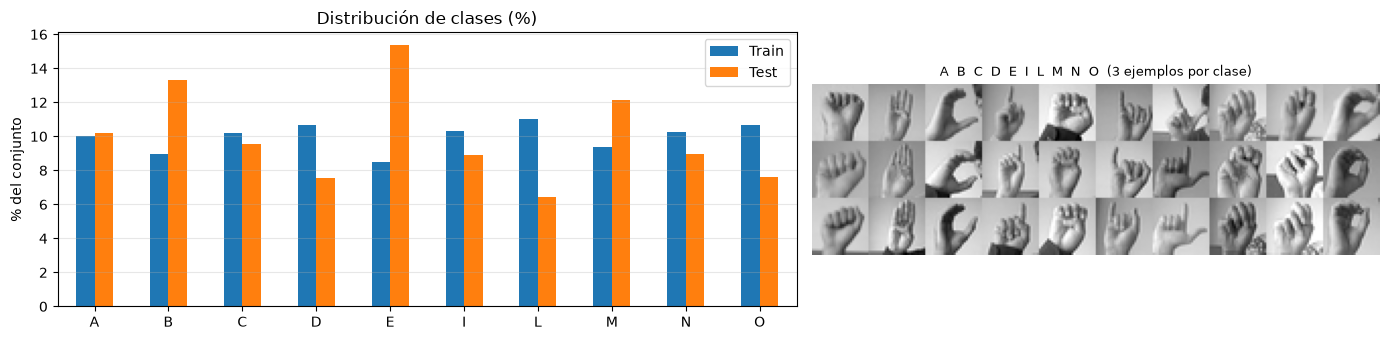

Distancia mediana al vecino más cercano en Train · desde Train: 0.43 · desde Test: 2.45
1-NN 'validación aleatoria' (dejando una fuera en Train): 99.98%
1-NN sobre Test oficial:                                 88.75%


In [4]:
def vecino_mas_cercano(a: np.ndarray, b: np.ndarray, misma_matriz: bool, bloque: int = 1024):
    """
    Distancia euclidiana de cada fila de `a` a su fila más cercana en `b` (e índice de esa fila).

    Usa ||x-y||² = ||x||² + ||y||² - 2·x·y por bloques, para no crear una matriz N×N completa.
    Con `misma_matriz=True` se excluye la distancia de cada imagen consigo misma.
    """
    nb = (b ** 2).sum(axis=1)
    dist, idx = np.empty(len(a), np.float32), np.empty(len(a), np.int64)
    for ini in range(0, len(a), bloque):
        blk = a[ini:ini + bloque]
        d2 = (blk ** 2).sum(axis=1)[:, None] + nb[None, :] - 2.0 * blk @ b.T
        if misma_matriz:
            d2[np.arange(len(blk)), ini + np.arange(len(blk))] = np.inf
        j = d2.argmin(axis=1)
        idx[ini:ini + bloque] = j
        dist[ini:ini + bloque] = np.sqrt(np.maximum(d2[np.arange(len(blk)), j], 0))
    return dist, idx


def analizar_dataset(x_train, y_train, x_test, y_test, nombres):
    """Distribución de clases, ejemplos por clase y diagnóstico de casi-duplicados (1-NN)."""
    conteo = pd.DataFrame({"Train": np.bincount(y_train), "Test": np.bincount(y_test)}, index=nombres)
    print("Imágenes por clase:")
    display(conteo.T)
    print(f"Razón máx/mín · train: {conteo.Train.max() / conteo.Train.min():.2f} · "
          f"test: {conteo.Test.max() / conteo.Test.min():.2f}")

    fig, axs = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [1.3, 1]})
    (conteo / conteo.sum() * 100).plot.bar(ax=axs[0], rot=0)
    axs[0].set(title="Distribución de clases (%)", ylabel="% del conjunto")
    axs[0].grid(axis="y", alpha=0.3)
    axs[1].axis("off")
    grilla = np.vstack([np.hstack([x_train[np.where(y_train == c)[0][k], :, :, 0] for c in range(len(nombres))])
                        for k in range(3)])
    axs[1].imshow(grilla, cmap="gray")
    axs[1].set_title("  ".join(nombres) + "  (3 ejemplos por clase)", fontsize=9)
    plt.tight_layout()
    plt.show()

    # Casi-duplicados: un 1-NN sin entrenamiento "dejando una fuera" dentro de Train simula una
    # validación aleatoria; el mismo 1-NN sobre Test mide la generalización a fotos distintas.
    xa = x_train.reshape(len(x_train), -1).astype(np.float32) / 255
    xb = x_test.reshape(len(x_test), -1).astype(np.float32) / 255
    d_tt, i_tt = vecino_mas_cercano(xa, xa, misma_matriz=True)
    d_te, i_te = vecino_mas_cercano(xb, xa, misma_matriz=False)
    print(f"Distancia mediana al vecino más cercano en Train · desde Train: {np.median(d_tt):.2f} · "
          f"desde Test: {np.median(d_te):.2f}")
    print(f"1-NN 'validación aleatoria' (dejando una fuera en Train): {(y_train[i_tt] == y_train).mean():.2%}")
    print(f"1-NN sobre Test oficial:                                 {(y_train[i_te] == y_test).mean():.2%}")
    return conteo


conteo_clases = analizar_dataset(x_train_full, y_train_full, x_test, y_test, CLASES)

**Interpretación.** El train de la variante está casi balanceado; el test, no (E tiene 2,4 veces más imágenes que L).
Por eso, cuando ambas difieren, el accuracy y el F1 macro pueden contar historias distintas.

El clasificador 1-NN no aprende nada: solo copia la etiqueta de la imagen más parecida. Aun así obtiene casi
100% "dejando una fuera" dentro de Train, porque casi toda imagen tiene una gemela levemente alterada. Una
validación aleatoria mediría memoria, no generalización. Por eso partimos por grupos (sección 3).

## 3. Preprocesamiento

### 3.1 Partición por grupos de casi-duplicados

1. Se unen en un mismo **grupo** las imágenes de train **de la misma clase** a distancia menor que
   `UMBRAL_GRUPOS`, y transitivamente sus vecinas (componentes conexas con *union-find*).
2. Se asignan **grupos completos** a train o a validación con `StratifiedGroupKFold`: ningún grupo queda partido
   y cada clase conserva aproximadamente su proporción.

**Cómo se eligió el umbral 2,25 (sin mirar el test).** Un primer intento con 1,0 dejó la validación saturada
(F1 = 1,000 en MLP y CNN): las variaciones rotadas o desplazadas de una misma foto quedaban a distancias
mayores. Repetimos la partición con varios umbrales (grupos dentro de cada clase; F1 macro de validación con
semilla 42 y 15 épocas; sin usar el test):

| Umbral | Grupos | Tamaño p25 / p50 / p75 | 1-NN | MLP | CNN |
|---|---|---|---|---|---|
| 1,00 | 2.847 | 1 / 2 / 5 | 0,989 | 0,972 | 1,000 |
| 1,50 | 1.014 | 2 / 5 / 17 | 0,802 | 0,817 | 0,980 |
| 2,00 | 476 | 4 / 20 / 34 | 0,628 | 0,854 | 0,954 |
| **2,25** | **347** | **19 / 21 / 41** | 0,582 | 0,761 | 0,946 |
| 2,50 | 241 | 20 / 21 / 60 | 0,483 | 0,583 | 0,761 |

Los grupos convergen a una unidad natural de **~21 imágenes por foto original**; con 2,25 el 75% de los
grupos ya la alcanza, y por encima crecen en múltiplos (se empiezan a unir fotos distintas). Partir una foto en dos grupos produce fuga; unir dos fotos solo endurece la validación. Por eso
preferimos pasarnos un poco a quedarnos cortos. Agrupar dentro de cada clase evita que el encadenamiento una
letras distintas.

In [5]:
def asignar_grupos(x: np.ndarray, y: np.ndarray, umbral: float = UMBRAL_GRUPOS, bloque: int = 1024) -> np.ndarray:
    """
    Devuelve un id de grupo por imagen: dos imágenes de la MISMA clase comparten grupo si están conectadas
    por una cadena de pares a distancia < umbral (componentes conexas, union-find con compresión de caminos).
    Usar las etiquetas de train para agrupar es legítimo: no usa información del test.
    """
    xf = x.reshape(len(x), -1).astype(np.float32) / 255
    n2 = (xf ** 2).sum(axis=1)
    padre = np.arange(len(xf))

    def raiz(a):
        while padre[a] != a:
            padre[a] = padre[padre[a]]
            a = padre[a]
        return a

    for ini in range(0, len(xf), bloque):
        d2 = n2[ini:ini + bloque, None] + n2[None, :] - 2.0 * xf[ini:ini + bloque] @ xf.T
        filas, cols = np.nonzero(d2 < umbral ** 2)
        for i, j in zip((filas + ini).tolist(), cols.tolist()):
            if j > i and y[i] == y[j]:
                ri, rj = raiz(i), raiz(j)
                if ri != rj:
                    padre[rj] = ri
    return np.array([raiz(i) for i in range(len(xf))])


def particionar_por_grupos(x, y, grupos, semilla: int = 42):
    """
    Partición train/validación (~80/20) que nunca separa un grupo y estratifica por clase.
    Verifica explícitamente que no haya grupos compartidos (prueba de no-fuga).
    """
    divisor = StratifiedGroupKFold(n_splits=round(1 / FRACCION_VALIDACION), shuffle=True, random_state=semilla)
    idx_tr, idx_val = next(divisor.split(x, y, groups=grupos))
    assert not set(grupos[idx_tr]) & set(grupos[idx_val]), "Fuga: un grupo quedó en train y validación"
    return idx_tr, idx_val


grupos = asignar_grupos(x_train_full, y_train_full)
idx_tr, idx_val = particionar_por_grupos(x_train_full, y_train_full, grupos)
tam = pd.Series(grupos).value_counts()
print(f"Grupos: {len(tam)} · tamaño p25/p50/p75: {tam.quantile(.25):.0f}/{tam.median():.0f}/{tam.quantile(.75):.0f} · máximo {tam.max()} · "
      f"grupos con >1 clase: {(pd.DataFrame({'g': grupos, 'y': y_train_full}).groupby('g').y.nunique() > 1).sum()}")
print(f"Train: {len(idx_tr)} ({len(idx_tr) / len(grupos):.1%}) · Validación: {len(idx_val)} ({len(idx_val) / len(grupos):.1%})")
display(pd.DataFrame({"Train %": np.bincount(y_train_full[idx_tr]) / len(idx_tr) * 100,
                      "Val %": np.bincount(y_train_full[idx_val]) / len(idx_val) * 100},
                     index=CLASES).round(1).T)
np.save(DIR_SALIDA / "grupos_variante.npy", grupos)   # reproducibilidad: ids de grupo usados

Grupos: 347 · tamaño p25/p50/p75: 19/21/41 · máximo 345 · grupos con >1 clase: 0
Train: 8873 (79.0%) · Validación: 2365 (21.0%)


,A,B,C,D,E,I,L,M,N,O
Train %,10.5,7.5,10.3,10.7,8.7,10.5,11.2,9.5,10.4,10.7
Val %,8.3,14.6,9.6,10.3,7.9,9.7,10.5,9.1,9.7,10.3


### 3.2 Normalización y Data Augmentation

- **Normalización:** dividir por 255 lleva los píxeles a [0, 1]. Con entradas de escala pequeña y similar, los
  gradientes son más estables y el learning rate por defecto de Adam funciona bien. Es un preprocesamiento
  **siempre aplicado** (train, validación y test).
- **Data Augmentation:** rotación ±10°, traslación ±10% y zoom ±10%, **sin volteo horizontal** (volteado,
  una mano derecha pasa a ser izquierda). Se implementa como capas de Keras dentro del modelo: actúan **solo
  durante el entrenamiento** y se desactivan automáticamente en `evaluate`/`predict`. Esto corrige el error de
  las plantillas 3.4/3.5, donde la DA se definía pero nunca se aplicaba.

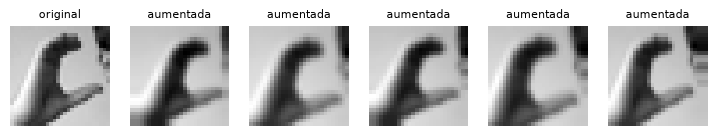

In [6]:
def preprocesar(x: np.ndarray) -> np.ndarray:
    """Convierte uint8 [0,255] a float32 [0,1]. No usa estadísticas de los datos, así que no hay fuga."""
    return x.astype(np.float32) / 255.0


def crear_aumentacion() -> tf.keras.Sequential:
    """Capas de augmentation (activas solo con training=True). fill_mode='nearest' evita bordes negros o espejados."""
    return tf.keras.Sequential([
        tf.keras.layers.RandomRotation(10 / 360, fill_mode="nearest"),   # factor = fracción de 2π → ±10°
        tf.keras.layers.RandomTranslation(0.10, 0.10, fill_mode="nearest"),
        tf.keras.layers.RandomZoom(0.10, fill_mode="nearest"),
    ], name="aumentacion")


DATOS = {
    "x_tr": preprocesar(x_train_full[idx_tr]), "y_tr": y_train_full[idx_tr],
    "x_val": preprocesar(x_train_full[idx_val]), "y_val": y_train_full[idx_val],
}
X_TEST, Y_TEST = preprocesar(x_test), y_test   # el test solo se usa en la sección de evaluación final

ejemplo = DATOS["x_tr"][:1]
aug = crear_aumentacion()
fig, axs = plt.subplots(1, 6, figsize=(9, 1.8))
axs[0].imshow(ejemplo[0, :, :, 0], cmap="gray")
axs[0].set_title("original", fontsize=8)
for ax in axs[1:]:
    ax.imshow(aug(ejemplo, training=True)[0, :, :, 0], cmap="gray")
    ax.set_title("aumentada", fontsize=8)
for ax in axs:
    ax.axis("off")
plt.show()

## 4. Construcción de los modelos

Una sola función construye todas las variantes a partir de un **diccionario de configuración**. Así, cada
experimento difiere solo en las claves que cambia, y la comparación MLP/CNN usa el mismo código de compilación.

| Arquitectura | Capas | Uso |
|---|---|---|
| `mlp` | Flatten → [Dense → (BN) → ReLU → (Dropout)] → Dense(10, softmax) | MLP de E3 (la de E2 cuando no hay regularización) |
| `cnn_e2` | Conv(32) → MaxPool → Flatten → Dense(128) → Dense(10) | Réplica de la CNN de E2 (referencia E0) |
| `cnn` | [Conv(f₁) → (BN) → ReLU → MaxPool] → [Conv(f₂) → (BN) → ReLU → MaxPool] → (Dropout) → Flatten → Dense → (BN) → ReLU → (Dropout) → Dense(10) | CNN de 2 bloques |

Entre paréntesis: componentes que se activan por configuración (técnicas de regularización).

In [7]:
CONFIG_BASE = {
    "arquitectura": "cnn", "neuronas": 128, "filtros": (32, 64),
    "dropout_conv": 0.0, "dropout_dense": 0.0, "l2": 0.0, "batchnorm": False,
    "aumentacion": False, "learning_rate": 1e-3, "batch_size": BATCH_SIZE,
    "early_stopping": False, "epocas": EPOCAS_MAX,
}


def construir_modelo(config: dict, n_clases: int = 10) -> tf.keras.Model:
    """
    Construye y compila una MLP o CNN según `config` (ver CONFIG_BASE).

    - L2 (`l2` > 0) se agrega a la pérdida como l2·Σw² sobre los kernels de las capas Conv/Dense ocultas.
    - Con BatchNorm, la capa previa no usa bias: BN ya incluye un desplazamiento aprendible (β).
    - Salida softmax + sparse_categorical_crossentropy: probabilidades por clase y etiquetas enteras.
    """
    c = {**CONFIG_BASE, **config}
    reg = tf.keras.regularizers.l2(c["l2"]) if c["l2"] > 0 else None
    capas = tf.keras.layers

    def bloque_denso(m):
        m.add(capas.Dense(c["neuronas"], use_bias=not c["batchnorm"], kernel_regularizer=reg))
        if c["batchnorm"]:
            m.add(capas.BatchNormalization())
        m.add(capas.Activation("relu"))
        if c["dropout_dense"] > 0:
            m.add(capas.Dropout(c["dropout_dense"]))

    modelo = tf.keras.Sequential(name=c["arquitectura"])
    modelo.add(tf.keras.Input(shape=(28, 28, 1)))
    if c["aumentacion"]:
        modelo.add(crear_aumentacion())

    if c["arquitectura"] == "mlp":
        modelo.add(capas.Flatten())
        bloque_denso(modelo)
    elif c["arquitectura"] == "cnn_e2":
        modelo.add(capas.Conv2D(32, 3, activation="relu"))
        modelo.add(capas.MaxPooling2D(2))
        modelo.add(capas.Flatten())
        modelo.add(capas.Dense(128, activation="relu"))
    elif c["arquitectura"] == "cnn":
        for f in c["filtros"]:
            modelo.add(capas.Conv2D(f, 3, use_bias=not c["batchnorm"], kernel_regularizer=reg))
            if c["batchnorm"]:
                modelo.add(capas.BatchNormalization())
            modelo.add(capas.Activation("relu"))
            modelo.add(capas.MaxPooling2D(2))
        if c["dropout_conv"] > 0:
            modelo.add(capas.Dropout(c["dropout_conv"]))
        modelo.add(capas.Flatten())
        bloque_denso(modelo)
    else:
        raise ValueError(f"Arquitectura desconocida: {c['arquitectura']}")

    modelo.add(capas.Dense(n_clases, activation="softmax"))
    modelo.compile(optimizer=tf.keras.optimizers.Adam(c["learning_rate"]),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


for nombre, cfg in [("MLP (E2)", {"arquitectura": "mlp"}), ("CNN E2", {"arquitectura": "cnn_e2"}),
                    ("CNN 2 bloques", {"arquitectura": "cnn"})]:
    print(f"{nombre:<14} parámetros: {construir_modelo(cfg).count_params():>9,}")

MLP (E2)       parámetros:   101,770
CNN E2         parámetros:   693,962
CNN 2 bloques  parámetros:   225,034


## 5–6. Entrenamiento y regularización

`entrenar()` usa **siempre** el conjunto de validación agrupado y **nunca** el test (corrige las plantillas 3.1.3 y
3.4). Early Stopping monitorea `val_loss` y, con `restore_best_weights=True`, devuelve los pesos de la mejor época,
no los de la última.

In [8]:
def entrenar(modelo, datos: dict, config: dict, verbose: int = 0):
    """
    Entrena con validación agrupada. Devuelve (historial: dict, segundos, mejor_epoca).

    La mejor época es la de menor val_loss; con Early Stopping son los pesos que quedan en el modelo.
    """
    c = {**CONFIG_BASE, **config}
    callbacks = []
    if c["early_stopping"]:
        callbacks.append(tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PACIENCIA, restore_best_weights=True))
    t0 = time.perf_counter()
    hist = modelo.fit(datos["x_tr"], datos["y_tr"], validation_data=(datos["x_val"], datos["y_val"]),
                      epochs=c["epocas"], batch_size=c["batch_size"], callbacks=callbacks, verbose=verbose)
    segundos = time.perf_counter() - t0
    mejor_epoca = int(np.argmin(hist.history["val_loss"])) + 1
    return hist.history, segundos, mejor_epoca

## 7. Evaluación

Las métricas se calculan con scikit-learn sobre predicciones en **modo inferencia** (sin Dropout ni DA activos).
El accuracy de entrenamiento que reporta Keras en `history` se promedia *durante* la época, con Dropout y DA
encendidos, y subestima el desempeño real sobre train. Por eso la **brecha de generalización** se calcula
reevaluando el modelo final sobre train y validación.

- **Precision** = TP/(TP+FP): de lo que predije como "M", ¿cuánto era M?
- **Recall** = TP/(TP+FN): de todas las M reales, ¿cuántas detecté?
- **F1** = 2·P·R/(P+R): media armónica; castiga que una de las dos sea baja.
- **Macro**: promedio simple entre clases (cada letra pesa igual).
- **ROC-AUC OvR macro**: para cada clase, la probabilidad de que el modelo puntúe más alto a una imagen de esa
  clase que a una de otra; luego se promedia. Mide la capacidad de ordenar, independiente del umbral.

In [9]:
def evaluar_modelo(modelo, x, y) -> dict:
    """Métricas de clasificación (macro) + predicciones y probabilidades, en modo inferencia."""
    prob = modelo.predict(x, verbose=0, batch_size=512)
    pred = prob.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, average="macro", zero_division=0),
        "recall": recall_score(y, pred, average="macro", zero_division=0),
        "f1": f1_score(y, pred, average="macro"),
        "roc_auc": roc_auc_score(y, prob, multi_class="ovr", average="macro"),
        "pred": pred, "prob": prob,
    }


def graficar_curvas(historiales: dict, titulo: str = "", mejor: dict | None = None):
    """Curvas de loss y accuracy (train vs validación) para uno o varios historiales {etiqueta: history}."""
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    for etiqueta, h in historiales.items():
        ep = np.arange(1, len(h["loss"]) + 1)
        for ax, m in zip(axs, ("loss", "accuracy")):
            linea, = ax.plot(ep, h[f"val_{m}"], label=f"{etiqueta} · validación")
            ax.plot(ep, h[m], "--", color=linea.get_color(), alpha=0.6, label=f"{etiqueta} · train")
            if mejor and etiqueta in mejor:
                ax.axvline(mejor[etiqueta], color=linea.get_color(), ls=":", alpha=0.7)
    axs[0].set(title=f"Loss {titulo}", xlabel="Época", ylabel="Pérdida (entropía cruzada)")
    axs[1].set(title=f"Accuracy {titulo}", xlabel="Época", ylabel="Accuracy")
    for ax in axs:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()


def graficar_matriz_confusion(y, pred, nombres, titulo: str = ""):
    """Matriz de confusión normalizada por fila (recall por clase) con los conteos anotados."""
    cm = confusion_matrix(y, pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    plt.figure(figsize=(6.5, 5.5))
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", xticklabels=nombres, yticklabels=nombres,
                vmin=0, vmax=1, cbar_kws={"label": "Proporción de la fila"})
    plt.title(f"Matriz de confusión {titulo}")
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.show()
    return cm


def reporte_por_clase(y, pred, nombres) -> pd.DataFrame:
    """Classification report de scikit-learn como DataFrame."""
    return pd.DataFrame(classification_report(y, pred, target_names=nombres, output_dict=True,
                                              zero_division=0)).T.round(3)

## 8. Registro y ejecución de experimentos

Cada experimento es un `id` + una configuración y se entrena una vez por semilla. Cada corrida agrega una fila a
`outputs/experimentos.csv`, y su historial se guarda en `outputs/historiales/`. Si una corrida ya existe, se
reutiliza: el proceso puede interrumpirse y retomarse sin repetir trabajo.

**El test no aparece aquí:** toda la experimentación decide con validación.

In [10]:
COLUMNAS_METRICAS = ["f1_val", "acc_val", "acc_train", "brecha", "loss_val", "roc_auc_val",
                     "mejor_epoca", "epocas", "segundos", "parametros"]


def _leer_registro() -> pd.DataFrame:
    """Lee el registro y conserva solo las corridas de la partición vigente (nunca mezcla particiones)."""
    if not CSV_EXPERIMENTOS.exists():
        return pd.DataFrame()
    reg = pd.read_csv(CSV_EXPERIMENTOS)
    return reg[reg["particion"] == PARTICION]


def _config_json(c: dict) -> str:
    """Serializa la configuración de forma canónica (claves ordenadas) para poder compararla."""
    return json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in sorted(c.items())})


def ejecutar_experimento(id_exp: str, config: dict, etapa: str, datos: dict = DATOS,
                         semillas: list = SEMILLAS) -> pd.DataFrame:
    """
    Entrena `config` con cada semilla (o reutiliza lo guardado) y devuelve las filas de esas corridas.

    Reutilización: si (id, semilla) ya existe, se reutiliza. Si la MISMA configuración ya se entrenó con esa
    semilla bajo otro id (por ejemplo, el valor vigente repetido en cada barrido de la etapa B), se copia esa
    corrida en vez de entrenar de nuevo: el resultado sería idéntico salvo por ruido numérico.
    """
    c = {**CONFIG_BASE, **config}
    cfg_txt = _config_json(c)
    filas = []
    for s in semillas:
        registro = _leer_registro()
        if len(registro):
            mismo_id = registro[(registro["id"] == id_exp) & (registro["semilla"] == s)]
            if len(mismo_id):
                filas.append(mismo_id.iloc[0].to_dict())
                continue
            misma_cfg = registro[(registro["config"] == cfg_txt) & (registro["semilla"] == s)]
            if len(misma_cfg):
                fila = {**misma_cfg.iloc[0].to_dict(), "id": id_exp, "etapa": etapa}
                origen = DIR_HIST / f"{misma_cfg.iloc[0]['id']}_s{s}.json"
                (DIR_HIST / f"{id_exp}_s{s}.json").write_text(origen.read_text())
                pd.DataFrame([fila]).to_csv(CSV_EXPERIMENTOS, mode="a", header=False, index=False)
                filas.append(fila)
                continue
        if not EJECUTAR_BUSQUEDA:
            raise RuntimeError(f"No hay resultados guardados para {id_exp} (semilla {s}). Use EJECUTAR_BUSQUEDA=True.")
        fijar_semilla(s)
        modelo = construir_modelo(c)
        hist, seg, mejor = entrenar(modelo, datos, c)
        ev_val = evaluar_modelo(modelo, datos["x_val"], datos["y_val"])
        acc_tr = evaluar_modelo(modelo, datos["x_tr"], datos["y_tr"])["accuracy"]
        fila = {"id": id_exp, "etapa": etapa, "particion": PARTICION, "arquitectura": c["arquitectura"],
                "semilla": s, "config": cfg_txt,
                "f1_val": ev_val["f1"], "acc_val": ev_val["accuracy"], "acc_train": acc_tr,
                "brecha": acc_tr - ev_val["accuracy"], "loss_val": float(min(hist["val_loss"])),
                "roc_auc_val": ev_val["roc_auc"], "mejor_epoca": mejor, "epocas": len(hist["loss"]),
                "segundos": seg, "parametros": modelo.count_params()}
        with open(DIR_HIST / f"{id_exp}_s{s}.json", "w") as fh:
            json.dump({k: [float(v) for v in vs] for k, vs in hist.items()}, fh)
        pd.DataFrame([fila]).to_csv(CSV_EXPERIMENTOS, mode="a", header=not CSV_EXPERIMENTOS.exists(), index=False)
        filas.append(fila)
        print(f"  {id_exp:<22} s={s:<5} F1val={fila['f1_val']:.4f} brecha={fila['brecha']:+.4f} "
              f"épocas={fila['epocas']} ({seg:.0f}s)")
    return pd.DataFrame(filas)


def cargar_historial(id_exp: str, semilla: int = SEMILLAS[0]) -> dict:
    with open(DIR_HIST / f"{id_exp}_s{semilla}.json") as fh:
        return json.load(fh)


def resumir(ids: list) -> pd.DataFrame:
    """Tabla media ± desviación estándar por experimento (en el orden de `ids`)."""
    reg = _leer_registro()
    reg = reg[reg["id"].isin(ids)]
    g = reg.groupby("id")[COLUMNAS_METRICAS]
    tabla = g.mean().add_suffix("_media").join(g.std().add_suffix("_sd")).loc[ids]
    cols = ["f1_val", "acc_val", "brecha", "mejor_epoca", "segundos"]
    salida = pd.DataFrame(index=tabla.index)
    for col in cols:
        salida[col] = [f"{m:.4f} ± {s:.4f}" if col not in ("mejor_epoca", "segundos") else f"{m:.1f} ± {s:.1f}"
                       for m, s in zip(tabla[f"{col}_media"], tabla[f"{col}_sd"])]
    salida["parametros"] = tabla["parametros_media"].astype(int)
    return salida

## Etapa E0 — Referencias: los modelos de E2 bajo la nueva validación

**Hipótesis:** con validación agrupada, la MLP y la CNN de E2 (sin regularización, 40 épocas fijas) mostrarán
una **brecha train−validación visible**, que en E2 quedaba oculta por la validación aleatoria. Esa brecha es lo
que la regularización debe reducir.

,f1_val,acc_val,brecha,mejor_epoca,segundos,parametros
id,,,,,,
E0-MLP,0.8066 ± 0.0068,0.8113 ± 0.0066,0.1886 ± 0.0065,28.3 ± 9.9,16.1 ± 0.4,101770
E0-CNN-E2,0.8478 ± 0.0097,0.8554 ± 0.0092,0.1446 ± 0.0092,9.3 ± 1.5,59.4 ± 1.9,693962


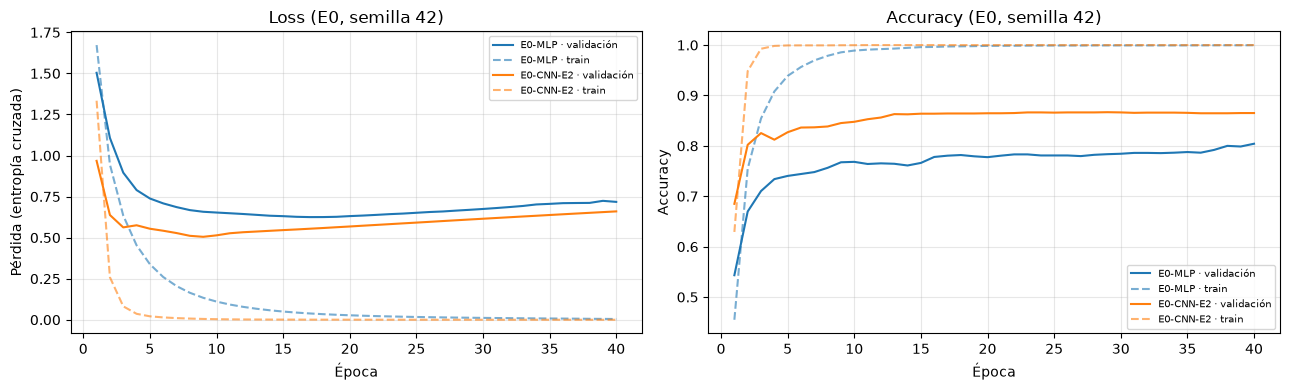

In [11]:
E0 = {
    "E0-MLP": {"arquitectura": "mlp"},
    "E0-CNN-E2": {"arquitectura": "cnn_e2"},
}
for id_exp, cfg in E0.items():
    ejecutar_experimento(id_exp, cfg, etapa="E0")
display(resumir(list(E0)))
graficar_curvas({k: cargar_historial(k) for k in E0}, titulo="(E0, semilla 42)")

**Interpretación E0.** Con la validación agrupada, los mismos modelos que en E2 parecían casi perfectos en
validación muestran ahora su desempeño real frente a fotos no vistas: MLP F1 ≈ 0,81 y CNN de E2 ≈ 0,85, con
**brechas train−validación grandes** (0,19 y 0,14). Ambos memorizan el train (≈100%) y la validación aleatoria
de E2 lo ocultaba. En las curvas, la pérdida de validación de la CNN de E2 toca su mínimo cerca de la época 9 y
luego sube mientras la de train sigue bajando: **sobreajuste clásico**. Hipótesis de E0 confirmada.

## Etapa A — Impacto de cada técnica de regularización

**Diseño controlado:** se parte del modelo sin regularización (*BASE*) y se agrega **una técnica por vez**,
con el mismo presupuesto de 40 épocas, para que cada efecto quede aislado. Las técnicas que cumplen la regla de
aceptación (fijada antes de ver resultados) se combinan en **ALL**, que será el punto de partida de la etapa B.

**Regla de aceptación:** una técnica se conserva si
1. mejora el F1 macro medio de validación en más que la desviación estándar entre semillas de BASE, **o**
2. reduce la brecha train−validación sin empeorar el F1 en más de 0,5 pp.

| Técnica | MLP | CNN | Qué esperamos (hipótesis) |
|---|---|---|---|
| ES | Early Stopping (`val_loss`, paciencia 5, restaura los mejores pesos) | ídem | Igual o mejor F1 con menos épocas |
| DO | Dropout 0,3 tras la capa oculta | 0,3 tras los bloques conv + 0,5 tras la densa | Menor brecha |
| L2 | λ = 1e-4 | ídem | Menor brecha; λ alto subajustaría |
| BN | BatchNorm tras cada capa oculta | ídem | Convergencia más rápida, leve regularización |
| DA | Rotación, traslación y zoom ±10% | ídem | Mejor generalización a fotos no vistas; puede necesitar más épocas |


MLP · sd del F1 de BASE entre semillas: 0.0068


,f1_val,acc_val,brecha,mejor_epoca,segundos,parametros
id,,,,,,
A-MLP-BASE,0.8066 ± 0.0068,0.8113 ± 0.0066,0.1886 ± 0.0065,28.3 ± 9.9,16.1 ± 0.4,101770
A-MLP-ES,0.7665 ± 0.0177,0.7683 ± 0.0187,0.2295 ± 0.0179,18.0 ± 4.6,10.2 ± 2.5,101770
A-MLP-DO,0.7927 ± 0.0107,0.7989 ± 0.0089,0.2003 ± 0.0086,26.0 ± 3.6,21.5 ± 5.2,101770
A-MLP-L2,0.8007 ± 0.0142,0.8051 ± 0.0154,0.1947 ± 0.0155,34.0 ± 3.5,17.3 ± 2.2,101770
A-MLP-BN,0.7676 ± 0.0189,0.7734 ± 0.0176,0.2266 ± 0.0176,6.0 ± 1.7,18.5 ± 4.4,102154
A-MLP-DA,0.7637 ± 0.0293,0.7772 ± 0.0356,0.1797 ± 0.0282,38.7 ± 1.2,35.9 ± 1.0,101770
A-MLP-ALL,0.8066 ± 0.0068,0.8113 ± 0.0066,0.1886 ± 0.0065,28.3 ± 9.9,16.1 ± 0.4,101770


,técnica,ΔF1 vs BASE,Δbrecha vs BASE,se conserva
0,ES,-0.0402,0.0409,False
1,DO,-0.0139,0.0117,False
2,L2,-0.0059,0.0061,False
3,BN,-0.0390,0.0381,False
4,DA,-0.0429,-0.0088,False


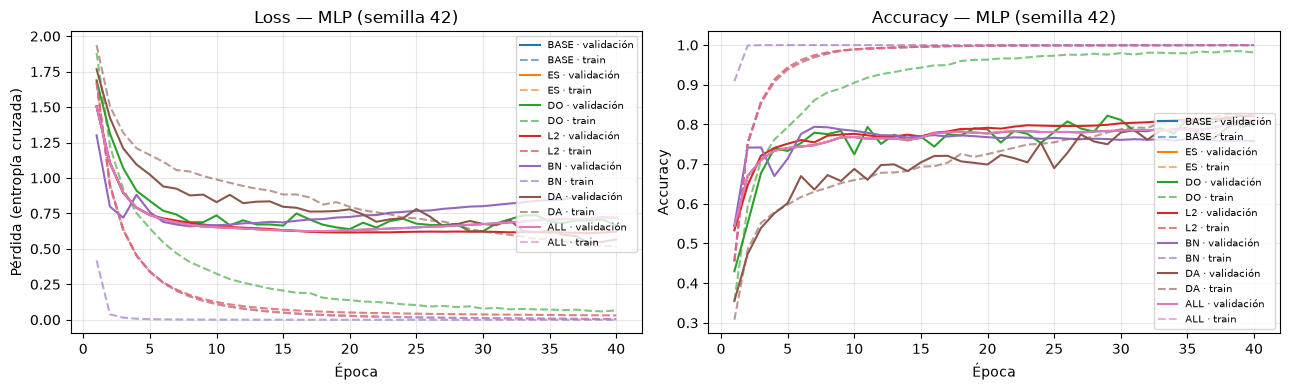

Configuración ALL MLP: {'arquitectura': 'mlp'}

CNN · sd del F1 de BASE entre semillas: 0.0049


,f1_val,acc_val,brecha,mejor_epoca,segundos,parametros
id,,,,,,
A-CNN-BASE,0.9454 ± 0.0049,0.9446 ± 0.0042,0.0554 ± 0.0042,5.7 ± 1.5,101.0 ± 52.1,225034
A-CNN-ES,0.9316 ± 0.0099,0.9315 ± 0.0095,0.0683 ± 0.0093,5.7 ± 1.5,31.7 ± 7.8,225034
A-CNN-DO,0.9585 ± 0.0069,0.9586 ± 0.0073,0.0414 ± 0.0073,20.0 ± 4.4,98.2 ± 12.4,225034
A-CNN-L2,0.9532 ± 0.0083,0.9532 ± 0.0080,0.0468 ± 0.0080,30.7 ± 9.5,91.7 ± 1.4,225034
A-CNN-BN,0.9595 ± 0.0103,0.9593 ± 0.0104,0.0407 ± 0.0104,9.0 ± 3.6,156.8 ± 14.0,225706
A-CNN-DA,0.9900 ± 0.0056,0.9901 ± 0.0057,0.0094 ± 0.0061,35.3 ± 4.5,90.5 ± 1.0,225034
A-CNN-ALL,0.9963 ± 0.0033,0.9963 ± 0.0033,0.0033 ± 0.0035,23.7 ± 5.5,169.9 ± 3.1,225706


,técnica,ΔF1 vs BASE,Δbrecha vs BASE,se conserva
0,ES,-0.0138,0.0130,False
1,DO,0.0131,-0.0140,True
2,L2,0.0078,-0.0086,True
3,BN,0.0141,-0.0147,True
4,DA,0.0446,-0.0460,True


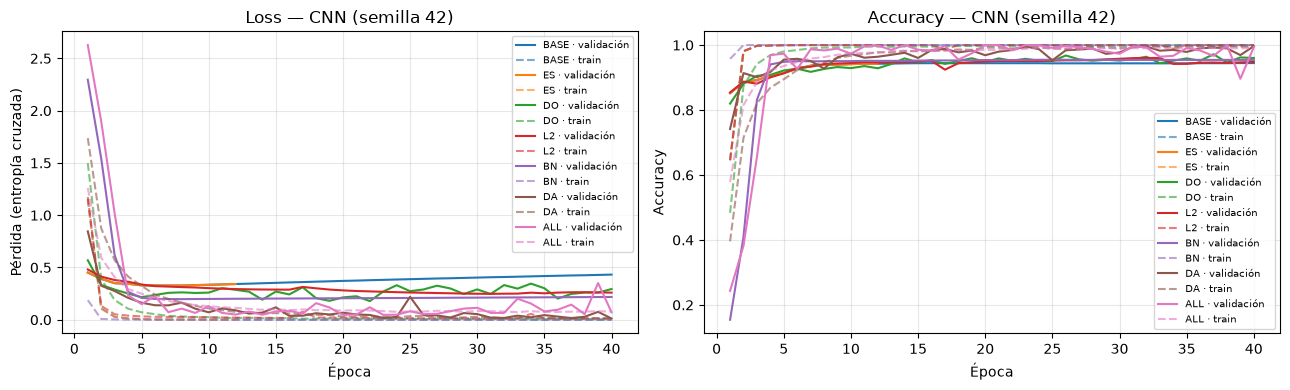

Configuración ALL CNN: {'arquitectura': 'cnn', 'dropout_conv': 0.3, 'dropout_dense': 0.5, 'l2': 0.0001, 'batchnorm': True, 'aumentacion': True}


In [12]:
TECNICAS = {
    "ES": {"early_stopping": True},
    "DO": {"mlp": {"dropout_dense": 0.3}, "cnn": {"dropout_conv": 0.3, "dropout_dense": 0.5}},
    "L2": {"l2": 1e-4},
    "BN": {"batchnorm": True},
    "DA": {"aumentacion": True},
}


def config_tecnica(arq: str, tecnica: str) -> dict:
    """Parámetros que activa una técnica para una arquitectura (algunas técnicas dependen de la arquitectura)."""
    t = TECNICAS[tecnica]
    return t[arq] if arq in t else t


def aceptar(cand: pd.Series, ref: pd.Series, sd_ref: float) -> bool:
    """Regla de aceptación (fijada antes de ver resultados)."""
    mejora_f1 = cand["f1_val"] - ref["f1_val"] > sd_ref
    reduce_brecha = (cand["brecha"] < ref["brecha"]) and (cand["f1_val"] >= ref["f1_val"] - 0.005)
    return bool(mejora_f1 or reduce_brecha)


def etapa_a(arq: str) -> tuple[dict, pd.DataFrame]:
    """Ejecuta BASE, BASE + cada técnica y ALL para una arquitectura. Devuelve (config ALL, tabla de decisión)."""
    pref = f"A-{arq.upper()}"
    base = {"arquitectura": arq}
    ejecutar_experimento(f"{pref}-BASE", base, etapa="A")
    for tec in TECNICAS:
        ejecutar_experimento(f"{pref}-{tec}", {**base, **config_tecnica(arq, tec)}, etapa="A")

    reg = _leer_registro()
    medias = reg.groupby("id")[["f1_val", "brecha"]].mean()
    sd_base = reg[reg["id"] == f"{pref}-BASE"]["f1_val"].std()
    decision, config_all = [], dict(base)
    for tec in TECNICAS:
        ok = aceptar(medias.loc[f"{pref}-{tec}"], medias.loc[f"{pref}-BASE"], sd_base)
        decision.append({"técnica": tec, "ΔF1 vs BASE": medias.loc[f"{pref}-{tec}", "f1_val"] - medias.loc[f"{pref}-BASE", "f1_val"],
                         "Δbrecha vs BASE": medias.loc[f"{pref}-{tec}", "brecha"] - medias.loc[f"{pref}-BASE", "brecha"],
                         "se conserva": ok})
        if ok:
            config_all.update(config_tecnica(arq, tec))
    ejecutar_experimento(f"{pref}-ALL", config_all, etapa="A")
    ids = [f"{pref}-BASE"] + [f"{pref}-{t}" for t in TECNICAS] + [f"{pref}-ALL"]
    print(f"\n{arq.upper()} · sd del F1 de BASE entre semillas: {sd_base:.4f}")
    display(resumir(ids))
    display(pd.DataFrame(decision).round(4))
    graficar_curvas({k.replace(f"{pref}-", ""): cargar_historial(k) for k in ids}, titulo=f"— {arq.upper()} (semilla 42)")
    return config_all, pd.DataFrame(decision)


CONFIG_A = {}
for arq in ("mlp", "cnn"):
    CONFIG_A[arq], _ = etapa_a(arq)
    print(f"Configuración ALL {arq.upper()}: {CONFIG_A[arq]}")

**Interpretación de la etapa A** (F1 macro de validación, media de 3 semillas):

- **CNN:** todas las técnicas, salvo Early Stopping, cumplieron la regla. La de mayor efecto fue **Data
  Augmentation**: F1 de 0,945 a 0,990 y brecha de 0,055 a 0,009. Tiene sentido: la validación agrupada evalúa
  fotos no vistas, y la DA enseña justamente variaciones de posición, rotación y escala. Dropout, L2 y BN aportan
  mejoras menores (≈ +0,01) con brechas más bajas. La combinación **ALL** llega a 0,996 con brecha de 0,003.
- **MLP:** **ninguna técnica ayudó** y ALL quedó igual a BASE. La DA bajó el F1 (0,764) aunque redujo algo la
  brecha: la MLP no tiene una estructura que le permita aprovechar variaciones espaciales, porque al aplanar la
  imagen cada desplazamiento es "otro" vector. Su limitación no es solo memorizar: es **cómo representa** la
  imagen. Es el argumento central de la comparación MLP vs CNN.
- **Early Stopping se rechazó en ambas.** Monitorea `val_loss`, que llega a su mínimo antes que el F1: el modelo
  sigue ganando aciertos varias épocas después, aunque se vuelve más confiado en sus errores (sube la entropía
  cruzada). No es que "no sirva": el criterio que vigila (pérdida) no coincide con la métrica que usamos para
  elegir (F1). Mejora propuesta: monitorear `val_accuracy` o aumentar la paciencia.

## Etapa B — Optimización de hiperparámetros: barrido coordinado

A partir de la configuración ALL de cada arquitectura se ajusta **un hiperparámetro a la vez** con una grilla de
valores (Grid Search 1-D), manteniendo todos los demás fijos en el mejor valor encontrado hasta ese momento.
Así se cumple el enunciado: "modificando un hiperparámetro a la vez utilizando Grid Search".

- **Orden:** learning rate → capacidad → dropout → L2 → batch size (de mayor a menor impacto esperado).
- **Regla de reemplazo:** un valor nuevo reemplaza al vigente solo si mejora el F1 macro medio de validación
  en más que la desviación estándar entre semillas del vigente. En caso de empate, se conserva el vigente
  (preferimos no cambiar sin evidencia).
- **Limitación declarada:** el barrido coordinado ignora interacciones (por ejemplo, learning rate × batch size)
  y su resultado depende del orden elegido.

In [13]:
GRILLAS = {
    "mlp": [("learning_rate", [3e-4, 1e-3, 3e-3]), ("neuronas", [128, 256, 512]),
            ("dropout_dense", [0.2, 0.3, 0.5]), ("l2", [0.0, 1e-4, 1e-3]), ("batch_size", [32, 64, 128])],
    "cnn": [("learning_rate", [3e-4, 1e-3, 3e-3]), ("filtros", [(16, 32), (32, 64), (64, 128)]),
            ("dropout_dense", [0.2, 0.3, 0.5]), ("l2", [0.0, 1e-4, 1e-3]), ("batch_size", [32, 64, 128])],
}


def barrido_coordinado(arq: str, config_inicial: dict) -> tuple[dict, pd.DataFrame]:
    """
    Grid Search 1-D por hiperparámetro, en el orden de GRILLAS[arq]. Devuelve la configuración final y
    una tabla con todas las configuraciones evaluadas (media ± sd de F1 de validación).
    """
    vigente = {**CONFIG_BASE, **config_inicial}
    filas = []
    for paso, (hp, valores) in enumerate(GRILLAS[arq], start=1):
        valores = list(dict.fromkeys(list(valores) + [vigente[hp]]))   # el valor vigente siempre compite
        resultados = {}
        for v in valores:
            id_exp = f"B{paso}-{arq.upper()}-{hp}={v}"
            df = ejecutar_experimento(id_exp, {**vigente, hp: v}, etapa="B")
            resultados[v] = (df["f1_val"].mean(), df["f1_val"].std(), df["brecha"].mean(), df["segundos"].mean())
            filas.append({"paso": f"B{paso}", "hiperparámetro": hp, "valor": str(v),
                          "F1 val (media)": resultados[v][0], "F1 val (sd)": resultados[v][1],
                          "brecha": resultados[v][2], "segundos": resultados[v][3], "vigente": v == vigente[hp]})
        media_vig, sd_vig = resultados[vigente[hp]][:2]
        mejor = max(resultados, key=lambda v: resultados[v][0])
        if resultados[mejor][0] - media_vig > sd_vig:
            print(f"B{paso} {hp}: {vigente[hp]} → {mejor} (F1 {media_vig:.4f} → {resultados[mejor][0]:.4f})")
            vigente[hp] = mejor
        else:
            print(f"B{paso} {hp}: se mantiene {vigente[hp]} (ninguna mejora supera la sd del vigente, {sd_vig:.4f})")
    tabla = pd.DataFrame(filas)
    display(tabla.round(4))
    return vigente, tabla


CONFIG_FINAL, TABLAS_B = {}, {}
for arq in ("mlp", "cnn"):
    print(f"\n===== Barrido coordinado {arq.upper()} =====")
    CONFIG_FINAL[arq], TABLAS_B[arq] = barrido_coordinado(arq, CONFIG_A[arq])
with open(DIR_SALIDA / "config_final.json", "w") as fh:
    json.dump({a: {k: (list(v) if isinstance(v, tuple) else v) for k, v in c.items()} for a, c in CONFIG_FINAL.items()},
              fh, indent=2)
print(json.dumps({a: c for a, c in CONFIG_FINAL.items()}, indent=2, default=str))


===== Barrido coordinado MLP =====
B1 learning_rate: se mantiene 0.001 (ninguna mejora supera la sd del vigente, 0.0068)
B2 neuronas: 128 → 512 (F1 0.8066 → 0.8181)


B3 dropout_dense: se mantiene 0.0 (ninguna mejora supera la sd del vigente, 0.0089)


B4 l2: se mantiene 0.0 (ninguna mejora supera la sd del vigente, 0.0089)
B5 batch_size: se mantiene 64 (ninguna mejora supera la sd del vigente, 0.0089)


,paso,hiperparámetro,valor,F1 val (media),F1 val (sd),brecha,segundos,vigente
0,B1,learning_rate,0.0003,0.7743,0.0078,0.2233,22.7255,False
1,B1,learning_rate,0.001,0.8066,0.0068,0.1886,16.1209,True
2,B1,learning_rate,0.003,0.7798,0.0246,0.2162,31.0190,False
3,B2,neuronas,128,0.8066,0.0068,0.1886,16.1209,True
4,B2,neuronas,256,0.8140,0.0071,0.1809,24.2269,False
5,B2,neuronas,512,0.8181,0.0089,0.1770,57.9689,False
6,B3,dropout_dense,0.2,0.8113,0.0128,0.1816,45.5932,False
7,B3,dropout_dense,0.3,0.7820,0.0120,0.2101,35.4638,False
8,B3,dropout_dense,0.5,0.7690,0.0270,0.2218,40.6556,False
9,B3,dropout_dense,0.0,0.8181,0.0089,0.1770,57.9689,True



===== Barrido coordinado CNN =====
B1 learning_rate: se mantiene 0.001 (ninguna mejora supera la sd del vigente, 0.0033)
B2 filtros: se mantiene (32, 64) (ninguna mejora supera la sd del vigente, 0.0033)
B3 dropout_dense: se mantiene 0.5 (ninguna mejora supera la sd del vigente, 0.0033)
B4 l2: se mantiene 0.0001 (ninguna mejora supera la sd del vigente, 0.0033)
B5 batch_size: se mantiene 64 (ninguna mejora supera la sd del vigente, 0.0033)


,paso,hiperparámetro,valor,F1 val (media),F1 val (sd),brecha,segundos,vigente
0,B1,learning_rate,0.0003,0.9925,0.0068,0.0067,366.0350,False
1,B1,learning_rate,0.001,0.9963,0.0033,0.0033,169.9408,True
2,B1,learning_rate,0.003,0.9140,0.1157,0.0303,193.4121,False
3,B2,filtros,"(16, 32)",0.9594,0.0251,0.0322,92.2917,False
4,B2,filtros,"(32, 64)",0.9963,0.0033,0.0033,169.9408,True
5,B2,filtros,"(64, 128)",0.9962,0.0047,0.0029,310.7103,False
6,B3,dropout_dense,0.2,0.9769,0.0171,0.0200,141.1688,False
7,B3,dropout_dense,0.3,0.9884,0.0182,0.0114,140.3455,False
8,B3,dropout_dense,0.5,0.9963,0.0033,0.0033,169.9408,True
9,B4,l2,0.0,0.9996,0.0004,-0.0004,137.9822,False


{
  "mlp": {
    "arquitectura": "mlp",
    "neuronas": 512,
    "filtros": [
      32,
      64
    ],
    "dropout_conv": 0.0,
    "dropout_dense": 0.0,
    "l2": 0.0,
    "batchnorm": false,
    "aumentacion": false,
    "learning_rate": 0.001,
    "batch_size": 64,
    "early_stopping": false,
    "epocas": 40
  },
  "cnn": {
    "arquitectura": "cnn",
    "neuronas": 128,
    "filtros": [
      32,
      64
    ],
    "dropout_conv": 0.3,
    "dropout_dense": 0.5,
    "l2": 0.0001,
    "batchnorm": true,
    "aumentacion": true,
    "learning_rate": 0.001,
    "batch_size": 64,
    "early_stopping": false,
    "epocas": 40
  }
}


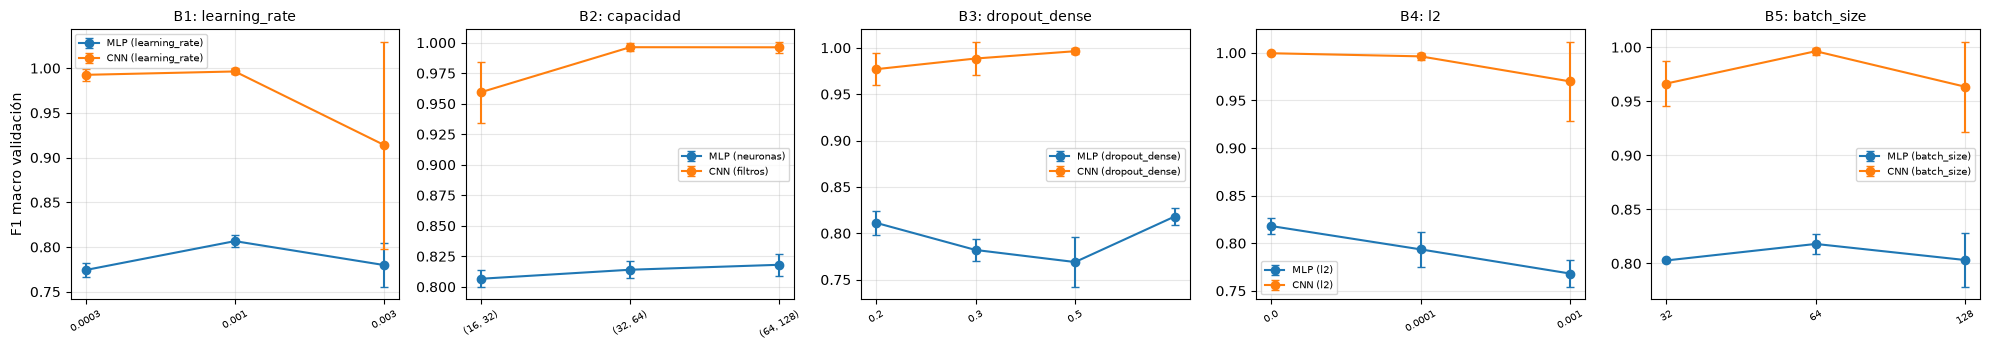

In [14]:
def graficar_barrido(tablas: dict):
    """F1 de validación (media ± sd) por valor de cada hiperparámetro, MLP vs CNN."""
    n_pasos = len(GRILLAS["mlp"])
    fig, axs = plt.subplots(1, n_pasos, figsize=(4 * n_pasos, 3.6))
    for i, ax in enumerate(axs):
        for arq, tabla in tablas.items():
            hp = GRILLAS[arq][i][0]
            t = tabla[tabla["paso"] == f"B{i + 1}"]
            ax.errorbar(range(len(t)), t["F1 val (media)"], yerr=t["F1 val (sd)"], marker="o", capsize=3,
                        label=f"{arq.upper()} ({hp})")
            ax.set_xticks(range(len(t)), t["valor"], rotation=30, fontsize=7)
        ax.set_title(f"B{i + 1}: {GRILLAS['mlp'][i][0] if GRILLAS['mlp'][i][0] != 'neuronas' else 'capacidad'}",
                     fontsize=10)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)
    axs[0].set_ylabel("F1 macro validación")
    plt.tight_layout()
    plt.show()


graficar_barrido(TABLAS_B)

**Interpretación de la etapa B.**

- **MLP:** solo la **capacidad** mejoró de forma demostrable. Con 512 neuronas, el F1 sube de 0,807 a 0,818
  (+0,011, por encima de la sd 0,007), con más parámetros (407 mil) a cambio. El learning rate por defecto
  (1e-3) fue el mejor: con 3e-4 aprende demasiado lento en 40 épocas y con 3e-3 es más inestable. Agregar
  Dropout o L2 a la MLP empeoró el resultado, coherente con la etapa A.
- **CNN:** **ningún cambio superó la regla** y se mantuvo la configuración ALL.
  - `lr = 3e-3` es **inestable** (sd 0,116: una semilla divergió).
  - Filtros (16, 32) quedan cortos (0,959); (64, 128) iguala a (32, 64) con el doble de parámetros y de tiempo,
    así que se conserva el más simple.
  - Caso límite: `l2 = 0` dio 0,9996 contra 0,9963. La mejora (0,0033) es **igual**, no mayor, a la sd
    del vigente (0,0033), así que la regla fijada de antemano conserva L2 = 1e-4. No la cambiamos después de ver
    el resultado.
- **Limitación:** con F1 de validación ≈ 0,996, la validación de la CNN está **casi saturada**. Las diferencias
  finas entre configuraciones de la CNN quedan dentro del ruido y la etapa B informa poco sobre ella. Tampoco
  exploramos interacciones (por ejemplo, learning rate × batch size).

## Etapa C — Evaluación final sobre el test oficial (una sola vez)

Hasta aquí **ninguna decisión usó el test**. Ahora se reentrenan la mejor MLP y la mejor CNN (configuraciones
finales de la etapa B) con las 3 semillas, se guardan en `models/` y se evalúan **una única vez** sobre las 3.244
imágenes del test oficial: las mismas que usó E2, así que la comparación con E2 es directa.

Para gráficos y XAI se usa el modelo de la **semilla 42**, elegida de antemano (no "el mejor en test", que sería
volver a usar el test para elegir).

**Incertidumbre del test.** El test también contiene variaciones de una misma foto, así que sus 3.244 imágenes
no son independientes. Para no sobrevalorar diferencias pequeñas, calculamos un intervalo de confianza del 95%
con *bootstrap por grupos*: se remuestrean grupos completos de casi-duplicados del test, no imágenes sueltas.

In [15]:
ACC_E2_TEST = {"mlp": 0.8758, "cnn": 0.9266}       # README / presentación E2 (mismo test, misma variante)


def entrenar_final(arq: str, config: dict, semillas: list = SEMILLAS) -> list:
    """
    Entrena (o carga, si ya existe en models/) el modelo final de una arquitectura con cada semilla.
    Devuelve una lista de dicts {semilla, modelo, historial, segundos, mejor_epoca}.
    """
    salida = []
    for s in semillas:
        ruta, ruta_h = DIR_MODELOS / f"final_{arq}_s{s}.keras", DIR_MODELOS / f"final_{arq}_s{s}_hist.json"
        if ruta.exists() and ruta_h.exists():
            info = json.loads(ruta_h.read_text())
            modelo = tf.keras.models.load_model(ruta)
        else:
            if not EJECUTAR_BUSQUEDA:
                raise RuntimeError(f"Falta {ruta.name}. Use EJECUTAR_BUSQUEDA=True.")
            fijar_semilla(s)
            modelo = construir_modelo(config)
            hist, seg, mejor = entrenar(modelo, DATOS, config)
            modelo.save(ruta)
            info = {"historial": {k: [float(v) for v in vs] for k, vs in hist.items()},
                    "segundos": seg, "mejor_epoca": mejor}
            ruta_h.write_text(json.dumps(info))
        salida.append({"semilla": s, "modelo": modelo, **info})
    return salida


def ic_bootstrap_grupos(y, pred, grupos_test, metrica, n=1000, semilla=0):
    """IC 95% de una métrica remuestreando GRUPOS completos de casi-duplicados del test."""
    rng = np.random.default_rng(semilla)
    ids = np.unique(grupos_test)
    por_grupo = {g: np.where(grupos_test == g)[0] for g in ids}
    valores = []
    for _ in range(n):
        idx = np.concatenate([por_grupo[g] for g in rng.choice(ids, len(ids), replace=True)])
        valores.append(metrica(y[idx], pred[idx]))
    return np.percentile(valores, [2.5, 97.5])


def tiempo_inferencia_ms(modelo, x, repeticiones=3) -> float:
    """Milisegundos por imagen al predecir el test completo (tras una pasada de calentamiento)."""
    modelo.predict(x[:256], verbose=0)
    t = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        modelo.predict(x, verbose=0, batch_size=512)
        t.append(time.perf_counter() - t0)
    return min(t) / len(x) * 1000


# Grupos de casi-duplicados DENTRO del test (mismo criterio que en train), solo para el bootstrap.
grupos_test = asignar_grupos(x_test, y_test)
print(f"Test: {len(Y_TEST)} imágenes en {len(np.unique(grupos_test))} grupos de casi-duplicados")

FINALES, filas_c = {}, []
for arq in ("mlp", "cnn"):
    FINALES[arq] = entrenar_final(arq, CONFIG_FINAL[arq])
    for f in FINALES[arq]:
        ev_t = evaluar_modelo(f["modelo"], X_TEST, Y_TEST)
        ev_v = evaluar_modelo(f["modelo"], DATOS["x_val"], DATOS["y_val"])
        f["ev_test"] = ev_t
        filas_c.append({"arquitectura": arq.upper(), "semilla": f["semilla"],
                        "acc_test": ev_t["accuracy"], "precision_test": ev_t["precision"],
                        "recall_test": ev_t["recall"], "f1_test": ev_t["f1"], "roc_auc_test": ev_t["roc_auc"],
                        "f1_val": ev_v["f1"], "brecha_val_test": ev_v["f1"] - ev_t["f1"],
                        "segundos_entrenamiento": f["segundos"],
                        "ms_por_imagen": tiempo_inferencia_ms(f["modelo"], X_TEST),
                        "parametros": f["modelo"].count_params()})
RESULTADOS_C = pd.DataFrame(filas_c)
RESULTADOS_C.to_csv(DIR_SALIDA / "resultados_test.csv", index=False)

metricas_c = ["acc_test", "precision_test", "recall_test", "f1_test", "roc_auc_test", "f1_val", "brecha_val_test",
              "segundos_entrenamiento", "ms_por_imagen", "parametros"]
g_c = RESULTADOS_C.groupby("arquitectura")[metricas_c]
media, sd = g_c.mean(), g_c.std()
TABLA_C = pd.DataFrame({m: [f"{media.loc[a, m]:.4f} ± {sd.loc[a, m]:.4f}" if m != "parametros"
                            else f"{int(media.loc[a, m]):,}" for a in media.index] for m in metricas_c},
                       index=media.index).T
TABLA_C.loc["acc_test E2 (referencia)"] = [f"{ACC_E2_TEST[a.lower()]:.4f}" for a in TABLA_C.columns]
print(f"Resultados en TEST (media ± sd entre {len(SEMILLAS)} semillas):")
display(TABLA_C)

for arq in ("mlp", "cnn"):
    f42 = FINALES[arq][0]
    for nombre, fn in [("accuracy", accuracy_score), ("F1 macro", lambda a, b: f1_score(a, b, average="macro"))]:
        lo, hi = ic_bootstrap_grupos(Y_TEST, f42["ev_test"]["pred"], grupos_test, fn)
        print(f"{arq.upper()} (semilla 42) · {nombre} test = {fn(Y_TEST, f42['ev_test']['pred']):.4f} "
              f"· IC95% por grupos [{lo:.4f}, {hi:.4f}]")

Test: 3244 imágenes en 155 grupos de casi-duplicados


Resultados en TEST (media ± sd entre 3 semillas):


arquitectura,CNN,MLP
acc_test,0.9998 ± 0.0004,0.8733 ± 0.0047
precision_test,0.9999 ± 0.0002,0.8667 ± 0.0052
recall_test,0.9998 ± 0.0003,0.8607 ± 0.0051
f1_test,0.9998 ± 0.0003,0.8605 ± 0.0053
roc_auc_test,1.0000 ± 0.0000,0.9821 ± 0.0007
f1_val,0.9963 ± 0.0033,0.8181 ± 0.0089
brecha_val_test,-0.0035 ± 0.0036,-0.0424 ± 0.0095
segundos_entrenamiento,136.6798 ± 1.2166,24.4956 ± 0.7480
ms_por_imagen,0.0694 ± 0.0000,0.0252 ± 0.0005
parametros,"225,706","407,050"


MLP (semilla 42) · accuracy test = 0.8681 · IC95% por grupos [0.8097, 0.9182]


MLP (semilla 42) · F1 macro test = 0.8557 · IC95% por grupos [0.7967, 0.9035]


CNN (semilla 42) · accuracy test = 1.0000 · IC95% por grupos [1.0000, 1.0000]


CNN (semilla 42) · F1 macro test = 1.0000 · IC95% por grupos [1.0000, 1.0000]


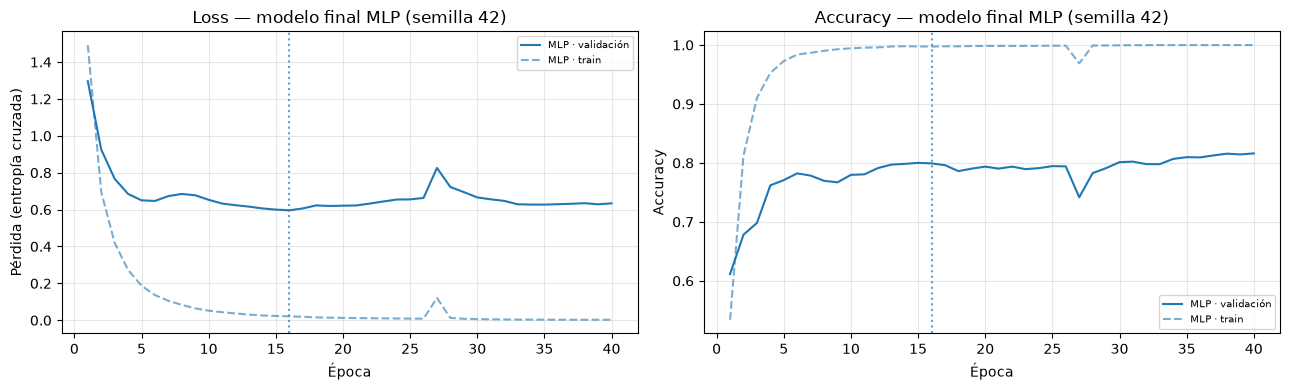

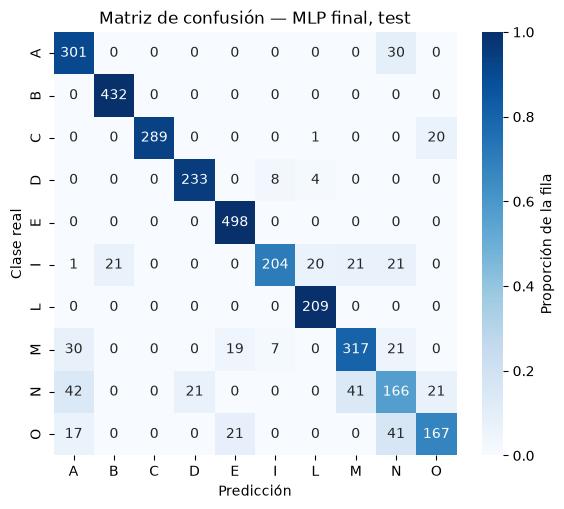

Classification report MLP (test, semilla 42):


,precision,recall,f1-score,support
A,0.770,0.909,0.834,331.000
B,0.954,1.000,0.976,432.000
C,1.000,0.932,0.965,310.000
D,0.917,0.951,0.934,245.000
E,0.926,1.000,0.961,498.000
I,0.932,0.708,0.805,288.000
L,0.893,1.000,0.944,209.000
M,0.836,0.805,0.820,394.000
N,0.595,0.570,0.582,291.000
O,0.803,0.679,0.736,246.000


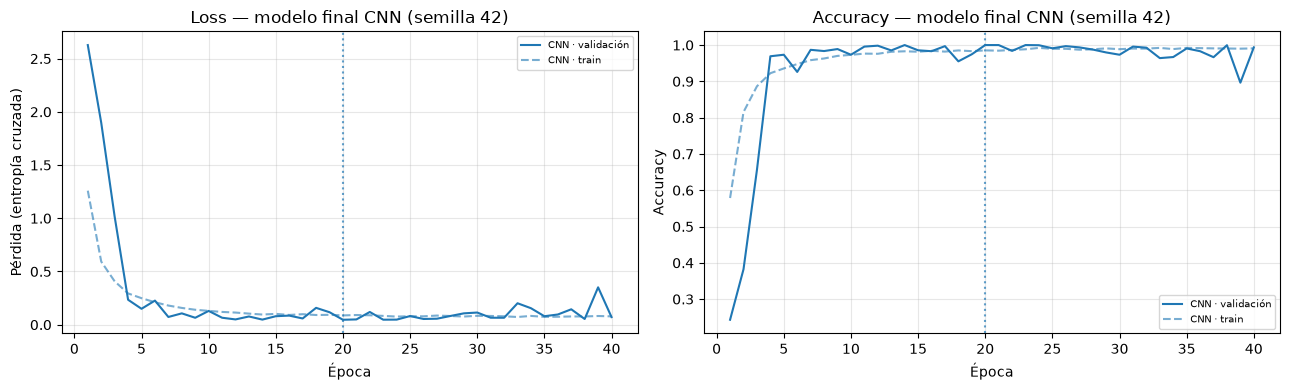

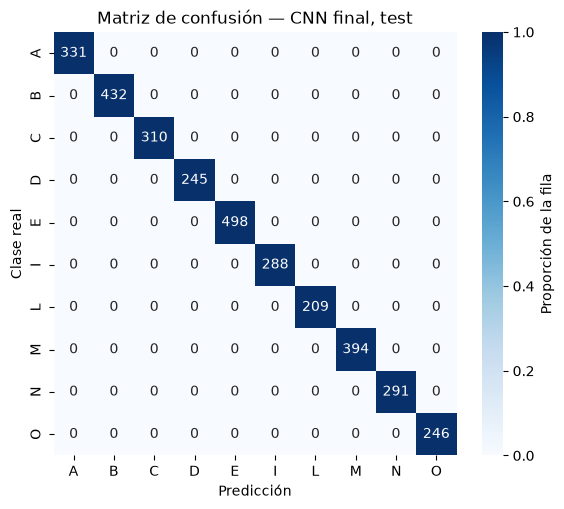

Classification report CNN (test, semilla 42):


,precision,recall,f1-score,support
A,1.0,1.0,1.0,331.0
B,1.0,1.0,1.0,432.0
C,1.0,1.0,1.0,310.0
D,1.0,1.0,1.0,245.0
E,1.0,1.0,1.0,498.0
I,1.0,1.0,1.0,288.0
L,1.0,1.0,1.0,209.0
M,1.0,1.0,1.0,394.0
N,1.0,1.0,1.0,291.0
O,1.0,1.0,1.0,246.0


In [16]:
for arq in ("mlp", "cnn"):
    f42 = FINALES[arq][0]
    graficar_curvas({arq.upper(): f42["historial"]}, titulo=f"— modelo final {arq.upper()} (semilla 42)",
                    mejor={arq.upper(): f42["mejor_epoca"]})
    graficar_matriz_confusion(Y_TEST, f42["ev_test"]["pred"], CLASES, titulo=f"— {arq.upper()} final, test")
    print(f"Classification report {arq.upper()} (test, semilla 42):")
    display(reporte_por_clase(Y_TEST, f42["ev_test"]["pred"], CLASES))

### C.2 Auditoría del resultado de test: ¿por qué la CNN llega a ~100%?

Un 99,98% en test es **sospechosamente alto** y además *supera* a la validación agrupada (99,6%). La MLP muestra
lo mismo (test 0,86 > validación 0,82). Si el test contuviera fotos o personas nuevas, esperaríamos lo
contrario. **Hipótesis:** el test oficial se generó a partir de las mismas fotos originales que el train,
con otras transformaciones (desplazamientos, rotaciones). Por eso la distancia en píxeles crudos parecía
grande, pero una CNN con DA las reconoce.

**Prueba (posterior a la evaluación; no se usa para elegir nada):** distancia de cada imagen a su vecina de
train más parecida **tolerando desplazamientos de ±3 px**, para el test y para la validación agrupada.

,mediana de la distancia a train,% bajo el umbral de agrupamiento,1-NN tolerante (accuracy)
Validación agrupada → train,1.541,61.818,0.911
Test oficial → train,1.171,83.416,0.986


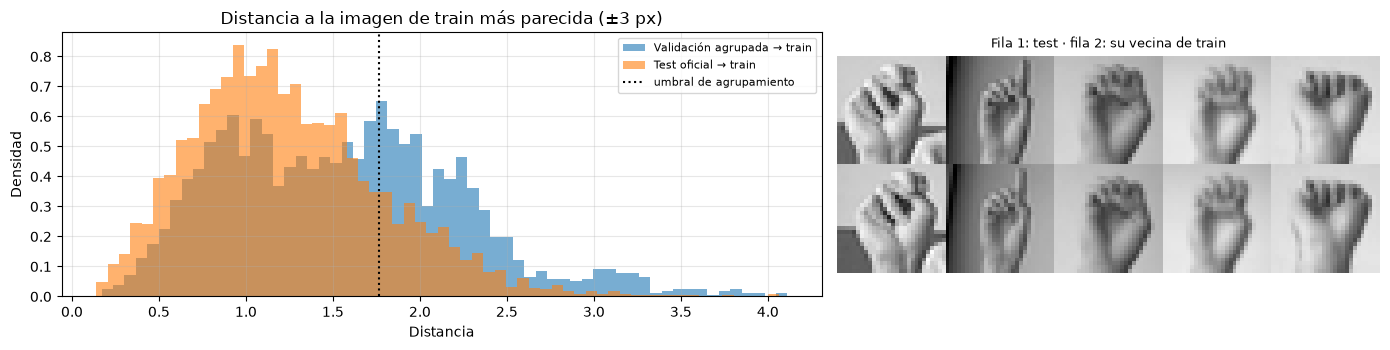

In [17]:
def distancia_tolerante(a: np.ndarray, b: np.ndarray, despl: int = 3):
    """
    Distancia mínima de cada imagen de `a` (N,28,28) a cualquier imagen de `b`, desplazando `a` hasta ±despl px.
    Se compara la zona central (28 − 2·despl px por lado) para que el desplazamiento no introduzca bordes.
    Devuelve (distancias, índices de la vecina en b).
    """
    c = slice(despl, 28 - despl)
    bf = b[:, c, c].reshape(len(b), -1)
    nb = (bf ** 2).sum(1)
    mejor_d, mejor_i = np.full(len(a), np.inf, np.float32), np.zeros(len(a), np.int64)
    for dy in range(-despl, despl + 1):
        for dx in range(-despl, despl + 1):
            af = np.roll(a, (dy, dx), axis=(1, 2))[:, c, c].reshape(len(a), -1)
            for ini in range(0, len(af), 1024):
                blk = af[ini:ini + 1024]
                d2 = (blk ** 2).sum(1)[:, None] + nb[None] - 2 * blk @ bf.T
                j = d2.argmin(1)
                d = np.sqrt(np.maximum(d2[np.arange(len(blk)), j], 0))
                m = d < mejor_d[ini:ini + 1024]
                mejor_d[ini:ini + 1024][m], mejor_i[ini:ini + 1024][m] = d[m], j[m]
    return mejor_d, mejor_i


umbral_central = UMBRAL_GRUPOS * np.sqrt((28 - 6) ** 2 / 28 ** 2)   # mismo umbral "por píxel" en 22×22
ref = DATOS["x_tr"][..., 0]
d_test, i_test = distancia_tolerante(X_TEST[..., 0], ref)
d_val, i_val = distancia_tolerante(DATOS["x_val"][..., 0], ref)
AUDITORIA_TEST = pd.DataFrame({
    "mediana de la distancia a train": [np.median(d_val), np.median(d_test)],
    "% bajo el umbral de agrupamiento": [(d_val < umbral_central).mean() * 100, (d_test < umbral_central).mean() * 100],
    "1-NN tolerante (accuracy)": [(DATOS["y_tr"][i_val] == DATOS["y_val"]).mean(), (DATOS["y_tr"][i_test] == Y_TEST).mean()],
}, index=["Validación agrupada → train", "Test oficial → train"]).round(3)
display(AUDITORIA_TEST)

fig, axs = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
axs[0].hist(d_val, bins=60, alpha=0.6, density=True, label="Validación agrupada → train")
axs[0].hist(d_test, bins=60, alpha=0.6, density=True, label="Test oficial → train")
axs[0].axvline(umbral_central, color="k", ls=":", label="umbral de agrupamiento")
axs[0].set(title="Distancia a la imagen de train más parecida (±3 px)", xlabel="Distancia", ylabel="Densidad")
axs[0].legend(fontsize=8)
axs[0].grid(alpha=0.3)
sel = np.random.default_rng(0).choice(len(X_TEST), 5, replace=False)
axs[1].imshow(np.vstack([np.hstack([X_TEST[i, :, :, 0] for i in sel]),
                         np.hstack([ref[i_test[i]] for i in sel])]), cmap="gray")
axs[1].set_title("Fila 1: test · fila 2: su vecina de train", fontsize=9)
axs[1].axis("off")
plt.tight_layout()
plt.show()

**Interpretación de la etapa C (test) — el hallazgo más importante de la auditoría.**

| | MLP final | CNN final | Referencia E2 (accuracy) |
|---|---|---|---|
| Accuracy test | 0,873 ± 0,005 | **0,9998 ± 0,0004** | MLP 0,876 · CNN 0,927 |
| F1 macro test | 0,861 ± 0,005 | **0,9998 ± 0,0003** | — |
| ROC-AUC OvR macro | 0,982 | 1,000 | — |
| F1 val − F1 test | −0,042 | −0,004 | — |
| Entrenamiento / inferencia | 24 s · 0,025 ms/img | 137 s · 0,069 ms/img | — |
| Parámetros | 407.050 | 225.706 | — |

1. **La CNN supera a la MLP en todas las métricas, en validación y en test**, con la mitad de parámetros. La
   diferencia (≈ 0,14 de F1) es muy superior a la variación entre semillas y al IC por grupos de la MLP
   ([0,80; 0,90]). Frente a E2, la CNN pasa de 92,7% a 99,98% en el **mismo** test; la MLP queda igual
   (87,6% → 87,3%), consistente con que ninguna regularización la ayudó.
2. **Pero el ~100% de la CNN no significa que reconozca señas de personas nuevas.** La auditoría C.2 muestra
   que, tolerando desplazamientos de ±3 px, **el 83% de las imágenes del test tiene una casi-copia en train**
   (1-NN tolerante: 98,6%). El test oficial reutiliza las **mismas fotos originales** del train con otras
   transformaciones. La CNN con DA (que aprendió a tolerar justamente esos desplazamientos y rotaciones) las
   reconoce. El test resultó **más fácil que nuestra validación agrupada** (62% bajo el umbral), que fue el
   estimador más exigente que tuvimos.
3. **Consecuencia:** ni el test oficial ni nuestra validación miden la generalización a **personas, fondos o
   cámaras nuevas**. Lo que sí podemos afirmar con evidencia: (a) bajo condiciones idénticas, la CNN generaliza
   mucho mejor que la MLP a variaciones de una misma foto; (b) la DA es la técnica que más contribuye;
   (c) la brecha validación−test de E2 (≈7 pp) se explicaba por casi-duplicados y por la falta de DA.
4. Esto explica también el "misterio" de E2: su CNN sin DA no toleraba los desplazamientos del test
   (92,7%), mientras que la validación aleatoria, llena de gemelas casi idénticas, le daba ~100%.

## Etapa D — Auditoría: XAI, atención al fondo, robustez y sesgos

### D.1 Grad-CAM (CNN)

Grad-CAM responde a la pregunta *¿qué regiones de la imagen hicieron subir la probabilidad de la clase predicha?*
1. Se toman las activaciones A de la última capa convolucional (tras su ReLU) y el gradiente de la probabilidad
   de la clase respecto de ellas.
2. El promedio espacial del gradiente da un peso α por filtro (cuánto importa ese filtro para la clase).
3. El mapa es ReLU(Σ α·A): solo se conservan las zonas que *aumentan* la clase. Luego se reescala a 28×28.

Se muestran 2 aciertos y hasta 2 errores por clase (no una sola imagen anecdótica).

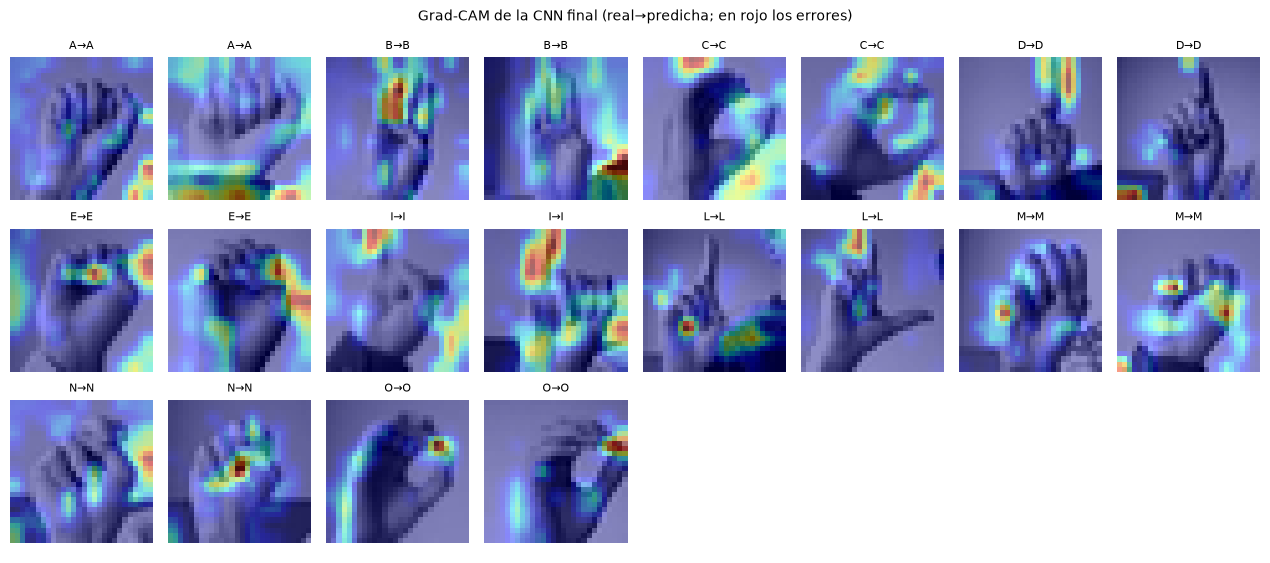

In [18]:
def capa_gradcam(modelo) -> tf.keras.layers.Layer:
    """Capa cuya salida usa Grad-CAM: la activación (ReLU) posterior a la última Conv2D."""
    capas = modelo.layers
    ultima_conv = max(i for i, c in enumerate(capas) if isinstance(c, tf.keras.layers.Conv2D))
    for c in capas[ultima_conv + 1:]:
        if isinstance(c, tf.keras.layers.Activation):
            return c
    return capas[ultima_conv]


def gradcam(modelo, imagenes: np.ndarray, clases: np.ndarray) -> np.ndarray:
    """Mapas Grad-CAM (N, 28, 28) normalizados a [0,1] para la clase indicada de cada imagen."""
    capa = capa_gradcam(modelo)
    x = tf.convert_to_tensor(imagenes)
    with tf.GradientTape() as cinta:
        # Se recorren las capas una a una (modo inferencia) para capturar la salida de la capa objetivo dentro
        # de la cinta. Un submodelo funcional sobre un Sequential recargado no conecta ese gradiente en Keras 3.
        h = x
        for c in modelo.layers:
            h = c(h, training=False)
            if c is capa:
                activaciones = h
        prob = h
        puntaje = tf.gather(prob, tf.convert_to_tensor(clases), axis=1, batch_dims=1)
    grad = cinta.gradient(puntaje, activaciones)
    alfa = tf.reduce_mean(grad, axis=(1, 2), keepdims=True)
    mapa = tf.nn.relu(tf.reduce_sum(alfa * activaciones, axis=-1))
    mapa = tf.image.resize(mapa[..., None], (28, 28))[..., 0].numpy()
    return mapa / (mapa.max(axis=(1, 2), keepdims=True) + 1e-8)


def seleccionar_ejemplos(y, pred, n_ok=2, n_err=2, semilla=0):
    """Por clase: n_ok aciertos y hasta n_err errores (elegidos al azar con semilla fija)."""
    rng = np.random.default_rng(semilla)
    sel = []
    for c in range(len(CLASES)):
        ok, err = np.where((y == c) & (pred == c))[0], np.where((y == c) & (pred != c))[0]
        sel += [(int(i), True) for i in rng.choice(ok, min(n_ok, len(ok)), replace=False)]
        sel += [(int(i), False) for i in rng.choice(err, min(n_err, len(err)), replace=False)]
    return sel


cnn42 = FINALES["cnn"][0]
pred_cnn = cnn42["ev_test"]["pred"]
ejemplos = seleccionar_ejemplos(Y_TEST, pred_cnn)
idx_ej = np.array([i for i, _ in ejemplos])
mapas = gradcam(cnn42["modelo"], X_TEST[idx_ej], pred_cnn[idx_ej])

columnas = 8
n_filas = int(np.ceil(len(ejemplos) / columnas))
fig, axs = plt.subplots(n_filas, columnas, figsize=(columnas * 1.6, n_filas * 1.9))
for ax in axs.ravel():
    ax.axis("off")
for ax, (i, ok), m in zip(axs.ravel(), ejemplos, mapas):
    ax.imshow(X_TEST[i, :, :, 0], cmap="gray")
    ax.imshow(m, cmap="jet", alpha=0.45)
    ax.set_title(f"{CLASES[Y_TEST[i]]}→{CLASES[pred_cnn[i]]}", fontsize=8, color="black" if ok else "red")
fig.suptitle("Grad-CAM de la CNN final (real→predicha; en rojo los errores)", fontsize=10)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "gradcam_cnn.png", dpi=120)
plt.show()

### D.2 ¿El modelo mira la mano o el fondo? (medida cuantitativa)

En la auditoría del dataset vimos que algunas clases tienen fondos característicos (posible **atajo**). Medimos
qué fracción de la "masa" de Grad-CAM cae en un **marco de 4 píxeles en el borde** de la imagen, sobre todo el
test. Si el mapa fuera uniforme, esa fracción sería 1 − 20²/28² = **0,49**. Valores claramente menores indican
atención concentrada en el centro, donde suele estar la mano. Es un indicador aproximado: la mano o el
antebrazo también pueden tocar el borde.

In [19]:
mapas_test = np.concatenate([gradcam(cnn42["modelo"], X_TEST[i:i + 256], pred_cnn[i:i + 256])
                             for i in range(0, len(X_TEST), 256)])
marco = np.ones((28, 28), bool)
marco[4:-4, 4:-4] = False
frac_borde = (mapas_test * marco).sum(axis=(1, 2)) / (mapas_test.sum(axis=(1, 2)) + 1e-8)
BORDE = pd.DataFrame({"clase": [CLASES[c] for c in Y_TEST], "frac_borde": frac_borde,
                      "acierto": pred_cnn == Y_TEST})
tabla_borde = BORDE.groupby("clase").frac_borde.mean().reindex(CLASES).to_frame("fracción en borde (media)")
tabla_borde["aciertos"] = BORDE[BORDE.acierto].groupby("clase").frac_borde.mean().reindex(CLASES)
tabla_borde["errores"] = BORDE[~BORDE.acierto].groupby("clase").frac_borde.mean().reindex(CLASES)
print(f"Fracción media de Grad-CAM en el borde: {frac_borde.mean():.3f} (uniforme = 0,490) · "
      f"aciertos {BORDE[BORDE.acierto].frac_borde.mean():.3f} · errores {BORDE[~BORDE.acierto].frac_borde.mean():.3f}")
display(tabla_borde.round(3).T)

Fracción media de Grad-CAM en el borde: 0.462 (uniforme = 0,490) · aciertos 0.462 · errores nan


clase,A,B,C,D,E,I,L,M,N,O
fracción en borde (media),0.644,0.45,0.492,0.389,0.494,0.519,0.446,0.376,0.413,0.348
aciertos,0.644,0.45,0.492,0.389,0.494,0.519,0.446,0.376,0.413,0.348
errores,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretación de Grad-CAM (D.1–D.2).**
- En la mayoría de las clases la atención se ubica en **la parte de la mano que define la seña**: la punta del
  dedo extendido en D, I y L; el anillo formado en O; la zona del puño y los nudillos en E, M y N.
- La fracción media en el borde (0,46) es apenas menor que la de un mapa uniforme (0,49). **No** es evidencia
  fuerte de concentración en la mano, porque en estas imágenes la mano ocupa casi todo el cuadro.
- **La clase A es la excepción:** 0,64 de su activación cae en el borde, y en los ejemplos aparecen zonas del
  fondo y de la franja inferior. Es un **posible atajo por fondo** (sesgo de entrada que el modelo explota),
  coherente con lo observado en las imágenes medias por clase en la auditoría del dataset. Como A acierta 100%
  en un test que comparte fotos con el train, ese atajo **no se notaría en el test**, pero podría fallar con
  otro fondo.
- **Limitación:** el mapa sale de una capa de 11×11 reescalada a 28×28 (baja resolución). Indica zonas, no
  píxeles.

### D.3 LIME en ambas redes (comparación de explicabilidad)

Grad-CAM no se puede aplicar a la MLP, porque no tiene capas convolucionales. Para comparar la explicabilidad
con **la misma herramienta**, usamos LIME en ambas redes:
1. divide la imagen en superpíxeles (SLIC);
2. genera muchas versiones apagando superpíxeles al azar;
3. ajusta un modelo lineal local que estima cuánto aporta cada superpíxel a la clase predicha.

Para cada imagen se pinta el **peso positivo de cada superpíxel**, normalizado (mismo estilo visual que
Grad-CAM), en una imagen de cada clase. También se mide qué fracción del peso positivo cae en el marco de 4 px
del borde, igual que con Grad-CAM.

C:\Users\kiwix\.venvs\tly1102-e3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fracción del peso LIME en el borde (media de las 10 imágenes; uniforme = 0,49) · MLP: 0.400 · CNN: 0.317


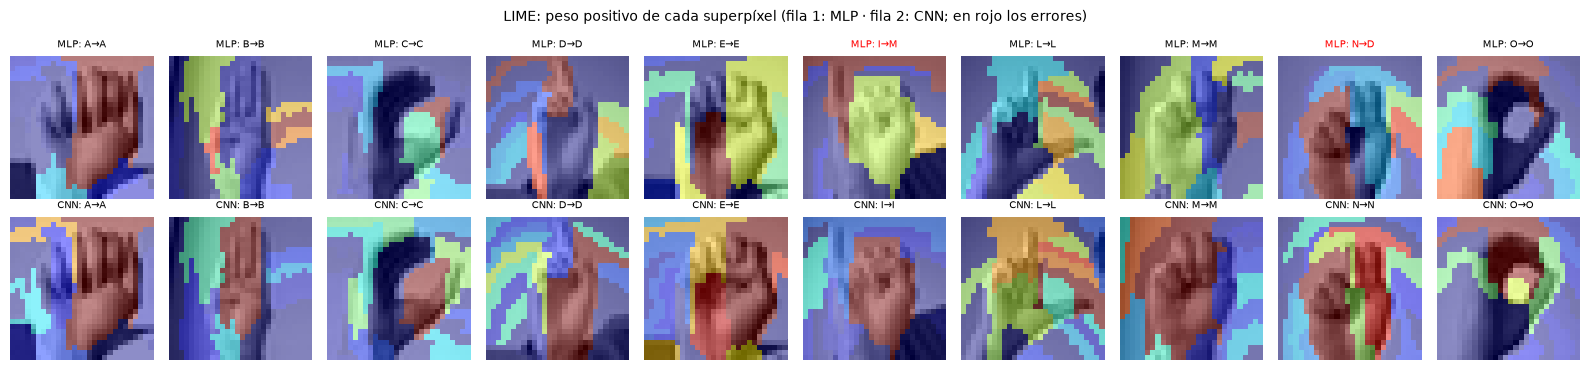

In [20]:
os.environ["TQDM_DISABLE"] = "1"      # LIME muestra una barra de progreso por explicación; la ocultamos
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm

segmentador = SegmentationAlgorithm("slic", n_segments=30, compactness=0.1, sigma=0.5, start_label=0,
                                    channel_axis=-1)
explicador = lime_image.LimeImageExplainer(random_state=42)


def clasificador_lime(modelo):
    """LIME trabaja con imágenes RGB; volvemos a 1 canal antes de predecir."""
    return lambda imgs: modelo.predict(imgs[..., :1].astype(np.float32), verbose=0, batch_size=512)


def explicar_lime(modelo, imagen: np.ndarray):
    """
    Devuelve (clase explicada, mapa 28×28 con el peso positivo de cada superpíxel normalizado a [0,1]).
    exp.local_exp[clase] es una lista (id_superpíxel, peso) del modelo lineal local.
    """
    rgb = np.repeat(imagen.astype(np.float64), 3, axis=-1)
    exp = explicador.explain_instance(rgb, clasificador_lime(modelo), top_labels=1, hide_color=0,
                                      num_samples=600, segmentation_fn=segmentador, random_seed=42)
    clase = exp.top_labels[0]
    mapa = np.zeros((28, 28))
    for segmento, peso in exp.local_exp[clase]:
        mapa[exp.segments == segmento] = max(peso, 0.0)       # solo evidencia a favor de la clase
    return clase, mapa / (mapa.max() + 1e-8)


mlp42 = FINALES["mlp"][0]
pred_mlp = mlp42["ev_test"]["pred"]
rng_lime = np.random.default_rng(1)
casos = [int(rng_lime.choice(np.where(Y_TEST == c)[0])) for c in range(len(CLASES))]
borde_lime = {"MLP": [], "CNN": []}
fig, axs = plt.subplots(2, len(casos), figsize=(len(casos) * 1.6, 3.8))
for j, i in enumerate(casos):
    for fila, (nombre, f) in enumerate([("MLP", mlp42), ("CNN", cnn42)]):
        clase, mapa_l = explicar_lime(f["modelo"], X_TEST[i])
        borde_lime[nombre].append((mapa_l * marco).sum() / (mapa_l.sum() + 1e-8))
        axs[fila, j].imshow(X_TEST[i, :, :, 0], cmap="gray")
        axs[fila, j].imshow(mapa_l, cmap="jet", alpha=0.45)
        axs[fila, j].set_title(f"{nombre}: {CLASES[Y_TEST[i]]}→{CLASES[clase]}", fontsize=7,
                               color="black" if clase == Y_TEST[i] else "red")
        axs[fila, j].axis("off")
fig.suptitle("LIME: peso positivo de cada superpíxel (fila 1: MLP · fila 2: CNN; en rojo los errores)", fontsize=10)
plt.tight_layout()
print("Fracción del peso LIME en el borde (media de las 10 imágenes; uniforme = 0,49) · "
      + " · ".join(f"{k}: {np.mean(v):.3f}" for k, v in borde_lime.items()))
plt.savefig(DIR_SALIDA / "lime_mlp_cnn.png", dpi=120)
plt.show()

**Interpretación de LIME (D.3).** Con la misma herramienta en ambas redes, la **CNN concentra el peso en la
mano** (B, D, I, M, O), mientras que la **MLP reparte más peso en el fondo** (en B, D y O destacan regiones
laterales). La fracción del peso en el borde lo cuantifica: MLP 0,40 vs CNN 0,32 (10 imágenes). Además, la MLP
se equivoca en I→M y N→D en esta muestra. **Conclusión de explicabilidad:** las decisiones de la CNN son más
fáciles de justificar porque se apoyan en la forma de la mano; las de la MLP dependen más de dónde caen los
píxeles. *Cautela:* son 10 imágenes y LIME depende de la segmentación y del muestreo aleatorio (semilla fija).

### D.4 Robustez ante perturbaciones controladas

Un modelo confiable no debería colapsar ante cambios que no alteran la seña: iluminación, ruido del sensor,
una leve rotación o desplazamiento. Evaluamos los modelos finales (semilla 42) sobre el test perturbado.
Ninguna de estas perturbaciones se usó para elegir modelos. La DA de la CNN incluye rotación ±10° y
traslación ±10%, así que en esas dos esperamos ventaja para la CNN.

In [21]:
from skimage.transform import rotate as sk_rotate


def perturbar(x: np.ndarray, tipo: str, semilla: int = 0) -> np.ndarray:
    """Aplica una perturbación nombrada al lote de imágenes (valores en [0,1])."""
    rng = np.random.default_rng(semilla)
    if tipo == "original":
        return x
    if tipo.startswith("brillo"):
        return np.clip(x * float(tipo.split("x")[1]), 0, 1)
    if tipo.startswith("ruido"):
        return np.clip(x + rng.normal(0, float(tipo.split("σ")[1]), x.shape), 0, 1).astype(np.float32)
    if tipo.startswith("rotación"):
        ang = float(tipo.split(" ")[1].rstrip("°"))
        return np.stack([sk_rotate(img, ang, mode="edge") for img in x]).astype(np.float32)
    if tipo.startswith("desplazamiento"):
        d = int(tipo.split(" ")[1].rstrip("px"))
        return np.pad(x, ((0, 0), (0, 0), (d, 0), (0, 0)), mode="edge")[:, :, :28, :]
    raise ValueError(tipo)


PERTURBACIONES = ["original", "brillo x0.7", "brillo x1.3", "ruido σ0.05", "ruido σ0.10",
                  "rotación 15°", "rotación -15°", "desplazamiento 4px"]
ROBUSTEZ = pd.DataFrame({nombre: [f1_score(Y_TEST, f["modelo"].predict(perturbar(X_TEST, p), verbose=0,
                                                                       batch_size=512).argmax(1), average="macro")
                                  for p in PERTURBACIONES]
                         for nombre, f in [("MLP", mlp42), ("CNN", cnn42)]}, index=PERTURBACIONES)
ROBUSTEZ["Δ MLP"] = ROBUSTEZ["MLP"] - ROBUSTEZ.loc["original", "MLP"]
ROBUSTEZ["Δ CNN"] = ROBUSTEZ["CNN"] - ROBUSTEZ.loc["original", "CNN"]
print("F1 macro en test bajo perturbaciones (semilla 42):")
display(ROBUSTEZ.round(4))
ROBUSTEZ.to_csv(DIR_SALIDA / "robustez.csv")

F1 macro en test bajo perturbaciones (semilla 42):


,MLP,CNN,Δ MLP,Δ CNN
original,0.8557,1.0000,0.0000,0.0000
brillo x0.7,0.8517,0.9966,-0.0039,-0.0034
brillo x1.3,0.8504,0.9891,-0.0053,-0.0109
ruido σ0.05,0.8515,0.9748,-0.0042,-0.0252
ruido σ0.10,0.8383,0.7730,-0.0174,-0.2270
rotación 15°,0.6414,0.9863,-0.2143,-0.0137
rotación -15°,0.5985,0.9356,-0.2572,-0.0644
desplazamiento 4px,0.2431,0.9318,-0.6126,-0.0682


**Interpretación de robustez (D.4).**
- **Geometría (rotación, desplazamiento): la gran diferencia.** Con un desplazamiento de 4 px, la MLP cae de
  0,86 a **0,24** y la CNN solo a 0,93. Con rotación de ±15°, la MLP cae a ~0,60–0,64 y la CNN se mantiene en
  0,94–0,99. Es la consecuencia práctica de la convolución (pesos compartidos + pooling) y de la DA.
- **Iluminación:** ambas son robustas (Δ ≤ 0,011).
- **Ruido fuerte (σ = 0,10): la CNN es la más frágil (0,77, Δ −0,23)**, mientras que la MLP cae apenas a 0,84.
  Hipótesis: los filtros convolucionales responden a bordes y texturas finas, y el ruido gaussiano crea bordes
  falsos. La DA no incluyó ruido. **Medida propuesta:** agregar ruido gaussiano y desenfoque a la DA, y
  eventualmente un suavizado previo.

### D.5 Sesgos: desempeño por clase y confusiones sistemáticas

Un buen F1 promedio puede esconder clases mal atendidas. Comparamos el recall por clase de ambas redes y
listamos las confusiones más frecuentes, considerando los sesgos del dataset (fondos por clase, pocas
fotos originales, señas parecidas M/N/A/E).

In [22]:
POR_CLASE = pd.DataFrame({
    "n test": np.bincount(Y_TEST),
    "recall MLP": recall_score(Y_TEST, pred_mlp, average=None),
    "recall CNN": recall_score(Y_TEST, pred_cnn, average=None),
    "F1 MLP": f1_score(Y_TEST, pred_mlp, average=None),
    "F1 CNN": f1_score(Y_TEST, pred_cnn, average=None),
    "Grad-CAM en borde": tabla_borde["fracción en borde (media)"].to_numpy(),
}, index=CLASES)
display(POR_CLASE.round(3).T)
POR_CLASE.to_csv(DIR_SALIDA / "por_clase.csv")

for nombre, pred in [("MLP", pred_mlp), ("CNN", pred_cnn)]:
    cm = confusion_matrix(Y_TEST, pred)
    np.fill_diagonal(cm, 0)
    top = sorted(((cm[i, j], CLASES[i], CLASES[j]) for i in range(10) for j in range(10) if cm[i, j]),
                 reverse=True)[:5]
    print(f"{nombre} · confusiones más frecuentes (real→predicha): " +
          ", ".join(f"{a}→{b} ({n})" for n, a, b in top))

,A,B,C,D,E,I,L,M,N,O
n test,331.000,432.000,310.000,245.000,498.000,288.000,209.000,394.000,291.000,246.000
recall MLP,0.909,1.000,0.932,0.951,1.000,0.708,1.000,0.805,0.570,0.679
recall CNN,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
F1 MLP,0.834,0.976,0.965,0.934,0.961,0.805,0.944,0.820,0.582,0.736
F1 CNN,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
Grad-CAM en borde,0.644,0.450,0.492,0.389,0.494,0.519,0.446,0.376,0.413,0.348


MLP · confusiones más frecuentes (real→predicha): N→A (42), O→N (41), N→M (41), M→A (30), A→N (30)
CNN · confusiones más frecuentes (real→predicha): 


**Interpretación de sesgos (D.5).**
- **MLP:** sus errores se concentran en las señas de **puño** (N, M, A) y en O. Recall de N = 0,57 y
  confusiones N→A, N→M, M→A, A→N y O→N. Son letras que se distinguen por la **posición del pulgar**, un
  detalle local de pocos píxeles. Es el mismo patrón que en E1/E2: un sesgo del sistema, porque la arquitectura
  no captura detalles locales invariantes a la posición.
- **CNN:** recall de 1,00 en todas las clases del test. Por lo visto en C.2, esto mide reconocimiento de
  variaciones de fotos ya vistas, **no** equidad entre clases frente a fotos nuevas.
- **Sesgos del dataset que persisten:**
  1. **Pocas fotos originales** (~21 variaciones por foto): la diversidad real de manos, tonos de piel, edades
     y fondos es mucho menor de lo que sugieren las 11.238 imágenes.
  2. **Fondos asociados a clases:** posible atajo en A (Grad-CAM, 0,64 en el borde).
  3. **Solo ASL estático:** no sirve para J ni Z ni para la Lengua de Señas Chilena.
  4. **Test no independiente del train**, así que no hay evidencia de generalización a personas nuevas.

**Medidas de mitigación propuestas (concretas):**

| Riesgo | Medida | Cómo verificarla |
|---|---|---|
| Test no independiente | Recolectar un test de **personas y fondos nuevos** (aunque sea pequeño) y particionar **por persona** | Brecha entre la validación por persona y ese test |
| Atajo por fondo (A) | DA con cambios de fondo y recortes aleatorios; recolectar fondos variados | Fracción de Grad-CAM en el borde de A < 0,49; desempeño estable con fondos sustituidos |
| Fragilidad al ruido | Ruido gaussiano y desenfoque en la DA | F1 con σ = 0,10 cerca del original |
| Baja diversidad de señantes | Documentarlo; recolectar datos de más personas; auditar el error por subgrupo si hay metadatos | Métricas por subgrupo |
| Uso indebido | Declarar el alcance (letras estáticas ASL); supervisión humana; no usarlo como traductor | — |

## Comparación objetiva MLP vs CNN

| Dimensión | MLP final (512 neuronas, sin regularización) | CNN final (2 bloques + DO + L2 + BN + DA) | Mejor |
|---|---|---|---|
| F1 macro validación agrupada | 0,818 ± 0,009 | **0,996 ± 0,003** | CNN |
| F1 macro test | 0,861 ± 0,005 | **0,9998 ± 0,0003** | CNN |
| ROC-AUC test | 0,982 | **1,000** | CNN |
| Brecha train−validación | 0,177 | **0,003** | CNN |
| Robustez a desplazamiento de 4 px | 0,24 | **0,93** | CNN |
| Robustez a rotación ±15° | 0,60–0,64 | **0,94–0,99** | CNN |
| Robustez a ruido σ = 0,10 | **0,84** | 0,77 | MLP |
| Parámetros | 407.050 | **225.706** | CNN |
| Tiempo de entrenamiento (40 épocas, CPU) | **24 s** | 137 s | MLP |
| Inferencia | **0,025 ms/img** | 0,069 ms/img | MLP (ambas despreciables) |
| Explicabilidad | Solo LIME; peso repartido en el fondo (0,40 en el borde) | Grad-CAM y LIME; foco en la mano (0,32), salvo un posible atajo en A | CNN |
| Respuesta a la regularización | Ninguna técnica ayudó | La DA fue decisiva | — |

**Arquitectura recomendada: la CNN.** Es superior en desempeño, generalización (validación agrupada),
robustez geométrica y explicabilidad, con menos parámetros. Su costo de entrenamiento es ~5,6 veces mayor,
pero sigue siendo bajo (≈2 min en CPU), y la inferencia es despreciable en ambas. Su debilidad medida (ruido
fuerte) tiene una mitigación concreta.

## Conclusiones

**1. Qué logramos.** Construimos un pipeline integrado y reproducible: carga → análisis → partición agrupada →
preprocesamiento y DA → construcción → entrenamiento → regularización → evaluación → auditoría → optimización,
con un registro de experimentos que se puede reanudar. Cada decisión se tomó con una regla fijada antes de ver
los resultados, con 3 semillas y sin tocar el test hasta el final. Corregimos errores de las plantillas 3.4/3.5:
DA sin aplicar, selección con el test, argumentos en el orden equivocado, diagnóstico con la última época.

**2. Hallazgo metodológico central.** El dataset contiene ~21 variaciones por foto original, en train y en test.
Una validación aleatoria mide memoria (1-NN 99,9%), y el test oficial reutiliza las mismas fotos (83% con
casi-copia en train). Por eso diseñamos una **validación por grupos**, elegida sin mirar el test. Con ella
aparecieron las brechas reales que E2 no veía, y resultó el estimador más exigente del proyecto.

**3. Resultados.** La CNN con regularización (la DA fue la técnica decisiva) supera claramente a la MLP: F1 de
validación 0,996 vs 0,818, robustez geométrica muy superior y explicaciones centradas en la mano. En el test
oficial llega a 99,98% (E2: 92,7%), cifra que **no** interpretamos como capacidad de reconocer señas de personas
nuevas.

**4. Limitaciones.**
- No hay datos de personas, fondos o cámaras nuevas, así que la generalización real es desconocida.
- La validación de la CNN quedó casi saturada (selección fina poco informativa).
- El barrido coordinado ignora interacciones.
- Early Stopping se evaluó con un criterio (`val_loss`) distinto de la métrica de selección (F1).
- El agrupamiento por píxeles es aproximado.
- Grad-CAM tiene baja resolución y LIME se mostró sobre 10 imágenes.
- La CNN es frágil ante ruido fuerte.

**5. Mejoras para una siguiente iteración (técnicamente viables):**
1. Test independiente con personas nuevas y partición **por persona**.
2. DA con ruido, desenfoque y cambios de fondo.
3. Early Stopping monitoreando `val_accuracy`, o con mayor paciencia.
4. Random Search corto para revisar interacciones.
5. Agrupamiento invariante a transformaciones (por ejemplo, embeddings de la propia CNN en vez de píxeles).
6. Métricas por subgrupo si se recolectan metadatos.

**6. Implicancias éticas.** Un 99,98% en test podría llevar a desplegar el sistema como "casi perfecto", y la
auditoría muestra que esa cifra no está respaldada para usuarios nuevos. Un sistema de apoyo a la comunicación de
personas sordas debe validarse con la comunidad usuaria y con datos representativos (señantes diversos, LSCh si
se usará en Chile), mantener supervisión humana y declarar su alcance.